# Error Detection Analysis

## Cell 1 — Imports

In [1]:
from pathlib import Path

if Path("/content").exists():
    from google.colab import drive
    drive.mount("/content/drive")
    import os
    os.chdir("/content/drive/MyDrive/msc_thesis/notebooks")
    print("Working directory:", Path.cwd())


Mounted at /content/drive
Working directory: /content/drive/MyDrive/msc_thesis/notebooks


In [2]:
from pathlib import Path
import warnings
import json
from itertools import combinations

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import rasterio
from rasterio.mask import mask
from rasterio.features import rasterize
from rasterio.transform import xy
from shapely.geometry import Point

from IPython.display import display

from scipy.stats import kruskal, mannwhitneyu
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    multilabel_confusion_matrix,
    classification_report,
    accuracy_score,
    hamming_loss,
    jaccard_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_fscore_support,
)
from sklearn.metrics.pairwise import rbf_kernel

import joblib

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 180)

## Cell 2 — User paths and settings

In [36]:

# Polygon inputs used to train the classifiers.
CORRECT_GPKG_PATH = Path(
    r"../inputs/polygon_analysis/pred_label_correct_samples.gpkg"
)
INCORRECT_GPKG_PATH = Path(
    r"../inputs/polygon_analysis/pred_label_incorrect_samples.gpkg"
)

CORRECT_LAYER = None
INCORRECT_LAYER = None

# Metric rasters used as predictor variables.
METRIC_RASTER_DIR = Path("../outputs/unified_unet_mcdo/metric_rasters")
METRIC_PATHS = {
    "predictive_uncertainty": METRIC_RASTER_DIR / "predictive_uncertainty.tif",
    "aleatoric_uncertainty": METRIC_RASTER_DIR / "aleatoric_uncertainty.tif",
    "epistemic_uncertainty": METRIC_RASTER_DIR / "epistemic_uncertainty.tif",
    "entropy": METRIC_RASTER_DIR / "entropy.tif",
    "disagreement": METRIC_RASTER_DIR / "disagreement.tif",
    "mutual_information": METRIC_RASTER_DIR / "mutual_information.tif",
    "calibration_error": METRIC_RASTER_DIR / "calibration_error.tif",
    "cross_entropy_loss": METRIC_RASTER_DIR / "cross_entropy_loss.tif",
    "softmax_confidence": METRIC_RASTER_DIR / "softmax_confidence.tif",
    "ce_minus_entropy": METRIC_RASTER_DIR / "ce_minus_entropy.tif",
    "brier_score": METRIC_RASTER_DIR / "brier_score.tif",
}

# Rasters sampled at exported validation points.
# Their class codes are converted as follows:
# 0 -> n, 1 -> d, 2 -> c
LABEL_CLASS_RASTER_PATH = Path(
    r"../inputs/label/para_three_class.tif"
)
MODEL_CLASS_RASTER_PATH = Path(
    r"../inputs/polygon_analysis/qgis_prediction_full_study_area.tif"
)

# ------------------------------------------------------------------
# EXPERIMENT NAME
# Change this string to create another independent experiment folder.
# ------------------------------------------------------------------
EXPERIMENT_NAME = "dt_rf500_hsic_rq_analysis_v1"
DRIVE_OUTPUT_ROOT = Path("../outputs")
DRIVE_OUTPUT_DIR = DRIVE_OUTPUT_ROOT / EXPERIMENT_NAME

# Local writes avoid repeated Google Drive filesystem operations in Colab.
RUNNING_IN_COLAB = Path("/content/drive/MyDrive").exists()
STAGE_INPUTS = RUNNING_IN_COLAB
LOCAL_OUTPUTS = RUNNING_IN_COLAB
OUTPUT_ROOT = (
    Path("/content/thesis_analysis_outputs")
    if LOCAL_OUTPUTS
    else DRIVE_OUTPUT_ROOT
)
OUTPUT_DIR = OUTPUT_ROOT / EXPERIMENT_NAME

RASTER_OUTPUT_DIR = OUTPUT_DIR / "rasters"
MASK_OUTPUT_DIR = OUTPUT_DIR / "label_error_masks"
TABLE_OUTPUT_DIR = OUTPUT_DIR / "tables"
FIGURE_OUTPUT_DIR = OUTPUT_DIR / "figures"
MODEL_OUTPUT_DIR = OUTPUT_DIR / "models"
VECTOR_OUTPUT_DIR = OUTPUT_DIR / "vectors"
VALIDATION_TABLE_DIR = TABLE_OUTPUT_DIR / "validation"

for directory in [
    OUTPUT_DIR,
    RASTER_OUTPUT_DIR,
    MASK_OUTPUT_DIR,
    TABLE_OUTPUT_DIR,
    FIGURE_OUTPUT_DIR,
    MODEL_OUTPUT_DIR,
    VECTOR_OUTPUT_DIR,
    VALIDATION_TABLE_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

SELECTED_POLYGONS_GPKG = (
    VECTOR_OUTPUT_DIR / "selected_balanced_training_polygons.gpkg"
)
TRAINING_PIXELS_CSV = (
    TABLE_OUTPUT_DIR / "balanced_training_pixels.csv"
)

# RQ1 descriptive and statistical outputs.
DESCRIPTIVE_STATS_CSV = (
    TABLE_OUTPUT_DIR / "metric_descriptive_statistics_by_class.csv"
)
KRUSKAL_WALLIS_CSV = (
    TABLE_OUTPUT_DIR / "metric_kruskal_wallis_tests.csv"
)
PAIRWISE_MANN_WHITNEY_CSV = (
    TABLE_OUTPUT_DIR / "metric_pairwise_mann_whitney_holm.csv"
)
BOXPLOT_DIR = FIGURE_OUTPUT_DIR / "metric_boxplots"
BOXPLOT_DIR.mkdir(parents=True, exist_ok=True)

# Decision Tree outputs.
DT_MODEL_PATH = MODEL_OUTPUT_DIR / "decision_tree_model.joblib"
DT_FEATURE_IMPORTANCE_CSV = (
    TABLE_OUTPUT_DIR / "decision_tree_feature_importance.csv"
)
DT_FEATURE_IMPORTANCE_PNG = (
    FIGURE_OUTPUT_DIR / "decision_tree_feature_importance.png"
)
DT_RULES_TXT = TABLE_OUTPUT_DIR / "decision_tree_rules.txt"
DT_DIAGRAM_PNG = FIGURE_OUTPUT_DIR / "decision_tree_diagram.png"
DT_METADATA_JSON = TABLE_OUTPUT_DIR / "decision_tree_metadata.json"

DT_PREDICTION_RASTER = (
    RASTER_OUTPUT_DIR / "decision_tree_prediction.tif"
)
DT_LABEL_ERROR_PROBABILITY_RASTER = (
    RASTER_OUTPUT_DIR / "decision_tree_label_error_probability.tif"
)

# Binary masks for excluding suspected label-error pixels.
# 1 = remove as suspected label error
# 0 = retain for training
# 255 = NoData
DT_ORIGINAL_LABEL_ERROR_MASK_RASTER = (
    MASK_OUTPUT_DIR / "decision_tree_original_label_error_mask.tif"
)

# NEW: 35% probability mask.
DT_LABEL_ERROR_35_MASK_RASTER = (
    MASK_OUTPUT_DIR
    / "decision_tree_label_error_probability_35pct_mask.tif"
)

DT_LABEL_ERROR_55_MASK_RASTER = (
    MASK_OUTPUT_DIR
    / "decision_tree_label_error_probability_55pct_mask.tif"
)
DT_LABEL_ERROR_85_MASK_RASTER = (
    MASK_OUTPUT_DIR
    / "decision_tree_label_error_probability_85pct_mask.tif"
)

LABEL_ERROR_PROBABILITY_THRESHOLD_35 = 0.35
LABEL_ERROR_PROBABILITY_THRESHOLD_55 = 0.55
LABEL_ERROR_PROBABILITY_THRESHOLD_85 = 0.85
LABEL_ERROR_MASK_NODATA = 255

# Random Forest outputs.
RF_N_ESTIMATORS = 500

# RAM-safe RF settings for standard Google Colab runtimes.
# The Decision Tree still uses the full balanced pixel training set.
RF_MAX_PIXELS_PER_CLASS = 20_000
RF_N_JOBS = 2
RF_MAX_DEPTH = 18
RF_MIN_SAMPLES_LEAF = 5
RF_MAX_SAMPLES = 0.70

RF_MODEL_PATH = (
    MODEL_OUTPUT_DIR / "random_forest_500_trees.joblib"
)
RF_FEATURE_IMPORTANCE_CSV = (
    TABLE_OUTPUT_DIR / "random_forest_feature_importance.csv"
)
RF_FEATURE_IMPORTANCE_PNG = (
    FIGURE_OUTPUT_DIR / "random_forest_feature_importance.png"
)
RF_METADATA_JSON = (
    TABLE_OUTPUT_DIR / "random_forest_metadata.json"
)

# HSIC outputs.
# HSIC has quadratic memory use. A balanced subset is used only for HSIC.
HSIC_MAX_SAMPLES_PER_CLASS = 500
HSIC_OVERALL_CSV = (
    TABLE_OUTPUT_DIR / "hsic_overall_three_class_scores.csv"
)
HSIC_ONE_VS_REST_CSV = (
    TABLE_OUTPUT_DIR / "hsic_one_vs_rest_scores.csv"
)
HSIC_COMBINED_CSV = TABLE_OUTPUT_DIR / "hsic_all_scores.csv"
HSIC_OVERALL_PNG = (
    FIGURE_OUTPUT_DIR / "hsic_overall_three_class_scores.png"
)
HSIC_ONE_VS_REST_PNG = (
    FIGURE_OUTPUT_DIR / "hsic_one_vs_rest_scores.png"
)

VALIDATION_POINTS_GPKG = (
    VECTOR_OUTPUT_DIR / "decision_tree_validation_points.gpkg"
)
VALIDATION_POINTS_LAYER = "decision_tree_validation_points"
N_VALIDATION_POINTS_PER_PREDICTED_CLASS = 50

# After manual auditing, point this to the edited validation GeoPackage.
AUDITED_VALIDATION_GPKG = Path(
    r"../inputs/polygon_analysis/group_3_all_metrics_validation.gpkg"
)
AUDITED_VALIDATION_LAYER = None

VALIDATED_POINTS_GPKG = (
    VECTOR_OUTPUT_DIR / "decision_tree_validation_points_validated.gpkg"
)
VALIDATED_POINTS_LAYER = "validated_points"

DT_LABEL_ERROR_THRESHOLD_CSV = (
    VALIDATION_TABLE_DIR
    / "decision_tree_label_error_probability_threshold_metrics.csv"
)
DT_MEMBERSHIP_CONFUSION_PNG = (
    FIGURE_OUTPUT_DIR / "decision_tree_membership_confusion_matrix.png"
)
DT_PERFORMANCE_METRICS_CSV = (
    VALIDATION_TABLE_DIR
    / "decision_tree_per_class_performance_metrics.csv"
)
DT_OVERALL_METRICS_CSV = (
    VALIDATION_TABLE_DIR
    / "decision_tree_overall_performance_metrics.csv"
)

CLASS_TO_CODE = {
    "label_error": 1,
    "model_error": 2,
    "correct_samples": 3,
}
CODE_TO_CLASS = {
    value: key
    for key, value in CLASS_TO_CODE.items()
}
VALID_DNC_CLASSES = {"d", "n", "c"}

# Decision Tree settings.
DECISION_TREE_MAX_DEPTH = 5
MIN_SAMPLES_LEAF = 1
CLASS_WEIGHT = "balanced"
RANDOM_SEED = 42

# Pixel balancing.
# None means downsample all classes to the smallest class.
MAX_PIXELS_PER_CLASS = None

DROP_NODATA = True
DROP_NONFINITE = True
ALL_TOUCHED = False

print(
    f"Experiment outputs will be written to: "
    f"{OUTPUT_DIR.resolve()}"
)

# Stage Notebook 3 metric rasters, manual polygons, and reference rasters.
# Source files remain on Drive.
import shutil

STAGED_INPUT_ROOT = Path("/content/thesis_analysis_inputs")

def stage_input(path: Path) -> Path:
    path = Path(path)

    if not STAGE_INPUTS:
        return path

    if not path.exists():
        return path

    resolved = path.resolve()
    drive_root = Path("/content/drive/MyDrive").resolve()

    try:
        relative = resolved.relative_to(drive_root)
    except ValueError:
        return path

    destination = STAGED_INPUT_ROOT / relative
    destination.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    if (
        not destination.exists()
        or destination.stat().st_size != path.stat().st_size
    ):
        print(f"Staging {path} -> {destination}")
        shutil.copy2(path, destination)

    return destination


CORRECT_GPKG_PATH = stage_input(CORRECT_GPKG_PATH)
INCORRECT_GPKG_PATH = stage_input(INCORRECT_GPKG_PATH)

METRIC_PATHS = {
    name: stage_input(path)
    for name, path in METRIC_PATHS.items()
}

LABEL_CLASS_RASTER_PATH = stage_input(LABEL_CLASS_RASTER_PATH)
MODEL_CLASS_RASTER_PATH = stage_input(MODEL_CLASS_RASTER_PATH)
AUDITED_VALIDATION_GPKG = stage_input(AUDITED_VALIDATION_GPKG)


def sync_outputs_to_drive():
    """Copy completed analysis outputs to persistent Drive storage."""

    if not LOCAL_OUTPUTS:
        print(f"Outputs already stored in: {OUTPUT_DIR}")
        return

    DRIVE_OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    transferred = 0

    for source in OUTPUT_DIR.rglob("*"):

        if not source.is_file():
            continue

        destination = (
            DRIVE_OUTPUT_DIR / source.relative_to(OUTPUT_DIR)
        )
        destination.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        if (
            not destination.exists()
            or destination.stat().st_size != source.stat().st_size
            or source.stat().st_mtime > destination.stat().st_mtime
        ):
            shutil.copy2(source, destination)
            transferred += 1

    print(
        f"Synced {transferred} files to {DRIVE_OUTPUT_DIR}"
    )


print("Input metric directory:", METRIC_RASTER_DIR)
print("Local working outputs:", OUTPUT_DIR)
print("Persistent Drive outputs:", DRIVE_OUTPUT_DIR)

Experiment outputs will be written to: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1
Input metric directory: ../outputs/unified_unet_mcdo/metric_rasters
Local working outputs: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1
Persistent Drive outputs: ../outputs/dt_rf500_hsic_rq_analysis_v1


## Cell 3 — General and polygon-class helper functions

In [4]:
REQUIRED_POLYGON_COLUMNS = [
    "label_class",
    "model_class",
    "validation_class",
    "actual_class",
    "area",
    "prodes_class",
]


def check_paths(paths):
    missing = [str(Path(path)) for path in paths if not Path(path).exists()]
    if missing:
        raise FileNotFoundError(
            "The following required files do not exist. Update Cell 2:\n"
            + "\n".join(missing)
        )


def read_vector(path, layer=None):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Vector file does not exist: {path}")
    return gpd.read_file(path) if layer is None else gpd.read_file(path, layer=layer)


def standardise_dnc(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    return value if value in VALID_DNC_CLASSES else np.nan


def classify_polygon_actual_class(row):
    '''
    Return:
        c = both label and model agree with manual validation
        l = label error only
        m = model error only
        b = both label and model error
    '''
    truth = row["validation_class"]
    label = row["label_class"]
    model = row["model_class"]

    label_correct = label == truth
    model_correct = model == truth

    if label_correct and model_correct:
        return "c"
    if (not label_correct) and model_correct:
        return "l"
    if label_correct and (not model_correct):
        return "m"
    return "b"


def prepare_polygon_input(gdf, source_name):
    missing = [
        column for column in REQUIRED_POLYGON_COLUMNS
        if column not in gdf.columns
    ]
    if missing:
        raise KeyError(f"{source_name} is missing columns: {missing}")

    out = gdf.copy()
    for column in ["label_class", "model_class", "validation_class"]:
        out[column] = out[column].map(standardise_dnc)

    out = out[
        out["validation_class"].notna()
        & out["label_class"].notna()
        & out["model_class"].notna()
        & out.geometry.notna()
        & (~out.geometry.is_empty)
    ].copy()

    if out.crs is None:
        raise ValueError(f"{source_name} has no CRS.")

    out["area"] = pd.to_numeric(out["area"], errors="coerce")
    out["actual_class"] = out.apply(classify_polygon_actual_class, axis=1)
    out["source_file"] = source_name
    return out


def select_balanced_polygons(correct_all, incorrect_all):
    '''
    Balance:
        correct deforestation,
        correct non-deforestation,
        label error only,
        model error only.

    The selected correct d/n polygons are merged into correct_samples.
    Both-error polygons are not used for three-class Decision Tree training.
    '''
    correct_d = correct_all[
        (correct_all["actual_class"] == "c")
        & (correct_all["validation_class"] == "d")
    ].sort_values("area", ascending=True, na_position="last")

    correct_n = correct_all[
        (correct_all["actual_class"] == "c")
        & (correct_all["validation_class"] == "n")
    ].sort_values("area", ascending=True, na_position="last")

    label_error = incorrect_all[
        incorrect_all["actual_class"] == "l"
    ].sort_values("area", ascending=True, na_position="last")

    model_error = incorrect_all[
        incorrect_all["actual_class"] == "m"
    ].sort_values("area", ascending=True, na_position="last")

    n_per_group = min(
        len(correct_d),
        len(correct_n),
        len(label_error),
        len(model_error),
    )
    if n_per_group == 0:
        raise ValueError(
            "Balanced selection is impossible because at least one required "
            "polygon group contains no rows."
        )

    selected_correct = pd.concat(
        [correct_d.head(n_per_group), correct_n.head(n_per_group)],
        ignore_index=True,
    )
    selected_incorrect = pd.concat(
        [label_error.head(n_per_group), model_error.head(n_per_group)],
        ignore_index=True,
    )

    selected_correct = gpd.GeoDataFrame(
        selected_correct,
        geometry="geometry",
        crs=correct_all.crs,
    )
    selected_incorrect = gpd.GeoDataFrame(
        selected_incorrect,
        geometry="geometry",
        crs=incorrect_all.crs,
    )

    return selected_correct, selected_incorrect, n_per_group

## Cell 4 — Read and select balanced training polygons

In [5]:
check_paths([CORRECT_GPKG_PATH, INCORRECT_GPKG_PATH])

correct_raw = read_vector(CORRECT_GPKG_PATH, CORRECT_LAYER)
incorrect_raw = read_vector(INCORRECT_GPKG_PATH, INCORRECT_LAYER)

correct_all = prepare_polygon_input(correct_raw, "correct_samples")
incorrect_all = prepare_polygon_input(incorrect_raw, "incorrect_samples")

selected_correct, selected_incorrect, n_per_group = select_balanced_polygons(
    correct_all,
    incorrect_all,
)

print(f"Selected polygons per source subgroup: {n_per_group}")
print(f"Selected correct polygons: {len(selected_correct)}")
print(f"Selected incorrect polygons: {len(selected_incorrect)}")

display(
    pd.DataFrame({
        "group": [
            "correct deforestation",
            "correct non-deforestation",
            "label error",
            "model error",
        ],
        "n_polygons": [
            int(((selected_correct["actual_class"] == "c") &
                 (selected_correct["validation_class"] == "d")).sum()),
            int(((selected_correct["actual_class"] == "c") &
                 (selected_correct["validation_class"] == "n")).sum()),
            int((selected_incorrect["actual_class"] == "l").sum()),
            int((selected_incorrect["actual_class"] == "m").sum()),
        ],
    })
)

Selected polygons per source subgroup: 98
Selected correct polygons: 196
Selected incorrect polygons: 196


,group,n_polygons
0,correct deforestation,98
1,correct non-deforestation,98
2,label error,98
3,model error,98


## Cell 5 — Raster and pixel-extraction helper functions

In [6]:
def validate_raster_alignment(metric_paths):
    profiles = {}
    for name, path in metric_paths.items():
        with rasterio.open(path) as src:
            profiles[name] = {
                "crs": src.crs,
                "transform": src.transform,
                "width": src.width,
                "height": src.height,
                "bounds": src.bounds,
                "nodata": src.nodata,
                "dtype": src.dtypes[0],
            }

    reference_name = next(iter(profiles))
    reference = profiles[reference_name]

    for name, profile in profiles.items():
        for key in ["crs", "transform", "width", "height"]:
            if profile[key] != reference[key]:
                raise ValueError(
                    f"Raster alignment mismatch: {name}.{key} differs from "
                    f"{reference_name}.{key}."
                )
    return profiles


def prepare_training_polygons(
    selected_correct,
    selected_incorrect,
    target_crs,
):
    def clean(gdf, class_name, source_group):
        out = gdf.copy()
        out = out[
            out.geometry.notna() & (~out.geometry.is_empty)
        ].copy()

        if out.crs is None:
            raise ValueError(f"{source_group} polygons have no CRS.")
        if str(out.crs) != str(target_crs):
            out = out.to_crs(target_crs)

        out["geometry"] = out.geometry.buffer(0)
        out = out[
            out.geometry.notna() & (~out.geometry.is_empty)
        ].copy()
        out["class_name"] = class_name
        out["source_group"] = source_group
        return out

    label_error = clean(
        selected_incorrect[selected_incorrect["actual_class"] == "l"],
        "label_error",
        "label_error",
    )
    model_error = clean(
        selected_incorrect[selected_incorrect["actual_class"] == "m"],
        "model_error",
        "model_error",
    )
    correct = clean(
        selected_correct,
        "correct_samples",
        "correct_samples",
    )

    combined = pd.concat(
        [label_error, model_error, correct],
        ignore_index=True,
    )
    combined = gpd.GeoDataFrame(
        combined,
        geometry="geometry",
        crs=target_crs,
    )
    combined["polygon_group"] = np.arange(len(combined), dtype=int)
    combined["area_raster_crs"] = combined.geometry.area
    return combined


def extract_pixels_for_polygons(polygons_gdf, metric_paths):
    rows = []
    metric_names = list(metric_paths)
    datasets = {
        name: rasterio.open(path)
        for name, path in metric_paths.items()
    }

    try:
        reference = datasets[metric_names[0]]

        for _, polygon in polygons_gdf.iterrows():
            geometry = polygon.geometry

            try:
                reference_array, cropped_transform = mask(
                    reference,
                    [geometry],
                    crop=True,
                    filled=False,
                    indexes=1,
                    all_touched=ALL_TOUCHED,
                )
            except ValueError:
                continue

            reference_array = np.ma.array(reference_array)
            height, width = reference_array.shape

            inside_polygon = rasterize(
                [(geometry, 1)],
                out_shape=(height, width),
                transform=cropped_transform,
                fill=0,
                dtype="uint8",
                all_touched=ALL_TOUCHED,
            ).astype(bool)

            valid = inside_polygon.copy()
            metric_arrays = {}

            for metric_name, dataset in datasets.items():
                array, _ = mask(
                    dataset,
                    [geometry],
                    crop=True,
                    filled=False,
                    indexes=1,
                    all_touched=ALL_TOUCHED,
                )
                data = np.ma.array(
                    array,
                    dtype="float64",
                ).filled(np.nan)

                if DROP_NODATA and dataset.nodata is not None:
                    data[data == float(dataset.nodata)] = np.nan
                if DROP_NONFINITE:
                    valid &= np.isfinite(data)

                metric_arrays[metric_name] = data

            row_indices, col_indices = np.where(valid)
            if len(row_indices) == 0:
                continue

            record = pd.DataFrame({
                "class_name": polygon["class_name"],
                "polygon_group": int(polygon["polygon_group"]),
                "source_group": polygon["source_group"],
            }, index=np.arange(len(row_indices)))

            for metric_name in metric_names:
                record[metric_name] = metric_arrays[metric_name][
                    row_indices,
                    col_indices,
                ]

            rows.append(record)

    finally:
        for dataset in datasets.values():
            dataset.close()

    if not rows:
        raise ValueError(
            "No valid pixels were extracted. Check CRS, raster extent, "
            "polygon geometry, and NoData values."
        )

    return pd.concat(rows, ignore_index=True)


def balance_pixels(df, max_pixels_per_class=None, random_seed=42):
    class_counts = df["class_name"].value_counts()
    n_per_class = int(class_counts.min())

    if max_pixels_per_class is not None:
        n_per_class = min(n_per_class, int(max_pixels_per_class))

    balanced_parts = []
    for class_name, class_df in df.groupby("class_name"):
        balanced_parts.append(
            class_df.sample(
                n=n_per_class,
                random_state=random_seed,
                replace=False,
            )
        )

    balanced = pd.concat(balanced_parts, ignore_index=True)
    return balanced, n_per_class, class_counts

## Cell 6 — Validate metric rasters and build training polygons

In [7]:
check_paths(METRIC_PATHS.values())
raster_profiles = validate_raster_alignment(METRIC_PATHS)
display(pd.DataFrame(raster_profiles).T)

with rasterio.open(next(iter(METRIC_PATHS.values()))) as src:
    raster_crs = src.crs

training_polygons = prepare_training_polygons(
    selected_correct,
    selected_incorrect,
    raster_crs,
)

if SELECTED_POLYGONS_GPKG.exists():
    SELECTED_POLYGONS_GPKG.unlink()

training_polygons.to_file(
    SELECTED_POLYGONS_GPKG,
    layer="selected_training_polygons",
    driver="GPKG",
)

display(
    training_polygons.groupby("class_name")
    .agg(
        n_polygons=("geometry", "count"),
        total_area=("area_raster_crs", "sum"),
        mean_area=("area_raster_crs", "mean"),
    )
    .reset_index()
)

print(f"Saved selected polygons: {SELECTED_POLYGONS_GPKG}")

,crs,transform,width,height,bounds,nodata,dtype
predictive_uncertainty,"(proj, zone, south, ellps, towgs84, units, no_defs)","(29.60881800899652, 0.0, 144603.36288141104, 0.0, -29.609443557474304, 9795688.361473627, 0.0, 0.0, 1.0)",14570,13232,"(144603.36288141104, 9403896.204321127, 576003.8412724903, 9795688.361473627)",-9999.0,float32
aleatoric_uncertainty,"(proj, zone, south, ellps, towgs84, units, no_defs)","(29.60881800899652, 0.0, 144603.36288141104, 0.0, -29.609443557474304, 9795688.361473627, 0.0, 0.0, 1.0)",14570,13232,"(144603.36288141104, 9403896.204321127, 576003.8412724903, 9795688.361473627)",-9999.0,float32
epistemic_uncertainty,"(proj, zone, south, ellps, towgs84, units, no_defs)","(29.60881800899652, 0.0, 144603.36288141104, 0.0, -29.609443557474304, 9795688.361473627, 0.0, 0.0, 1.0)",14570,13232,"(144603.36288141104, 9403896.204321127, 576003.8412724903, 9795688.361473627)",-9999.0,float32
entropy,"(proj, zone, south, ellps, towgs84, units, no_defs)","(29.60881800899652, 0.0, 144603.36288141104, 0.0, -29.609443557474304, 9795688.361473627, 0.0, 0.0, 1.0)",14570,13232,"(144603.36288141104, 9403896.204321127, 576003.8412724903, 9795688.361473627)",-9999.0,float32
disagreement,"(proj, zone, south, ellps, towgs84, units, no_defs)","(29.60881800899652, 0.0, 144603.36288141104, 0.0, -29.609443557474304, 9795688.361473627, 0.0, 0.0, 1.0)",14570,13232,"(144603.36288141104, 9403896.204321127, 576003.8412724903, 9795688.361473627)",-9999.0,float32
mutual_information,"(proj, zone, south, ellps, towgs84, units, no_defs)","(29.60881800899652, 0.0, 144603.36288141104, 0.0, -29.609443557474304, 9795688.361473627, 0.0, 0.0, 1.0)",14570,13232,"(144603.36288141104, 9403896.204321127, 576003.8412724903, 9795688.361473627)",-9999.0,float32
calibration_error,"(proj, zone, south, ellps, towgs84, units, no_defs)","(29.60881800899652, 0.0, 144603.36288141104, 0.0, -29.609443557474304, 9795688.361473627, 0.0, 0.0, 1.0)",14570,13232,"(144603.36288141104, 9403896.204321127, 576003.8412724903, 9795688.361473627)",-9999.0,float32
cross_entropy_loss,"(proj, zone, south, ellps, towgs84, units, no_defs)","(29.60881800899652, 0.0, 144603.36288141104, 0.0, -29.609443557474304, 9795688.361473627, 0.0, 0.0, 1.0)",14570,13232,"(144603.36288141104, 9403896.204321127, 576003.8412724903, 9795688.361473627)",-9999.0,float32
softmax_confidence,"(proj, zone, south, ellps, towgs84, units, no_defs)","(29.60881800899652, 0.0, 144603.36288141104, 0.0, -29.609443557474304, 9795688.361473627, 0.0, 0.0, 1.0)",14570,13232,"(144603.36288141104, 9403896.204321127, 576003.8412724903, 9795688.361473627)",-9999.0,float32
ce_minus_entropy,"(proj, zone, south, ellps, towgs84, units, no_defs)","(29.60881800899652, 0.0, 144603.36288141104, 0.0, -29.609443557474304, 9795688.361473627, 0.0, 0.0, 1.0)",14570,13232,"(144603.36288141104, 9403896.204321127, 576003.8412724903, 9795688.361473627)",-9999.0,float32


,class_name,n_polygons,total_area,mean_area
0,correct_samples,196,3.604509e+09,1.839035e+07
1,label_error,98,6.603257e+08,6.738017e+06
2,model_error,98,3.084776e+08,3.147731e+06


Saved selected polygons: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/vectors/selected_balanced_training_polygons.gpkg


## Cell 7 — Extract and balance pixel-level training data

In [8]:
pixels_raw = extract_pixels_for_polygons(
    training_polygons,
    METRIC_PATHS,
)

print("Raw pixel counts:")
display(
    pixels_raw["class_name"]
    .value_counts()
    .rename_axis("class_name")
    .reset_index(name="n_pixels")
)

pixels_balanced, n_per_class, raw_class_counts = balance_pixels(
    pixels_raw,
    max_pixels_per_class=MAX_PIXELS_PER_CLASS,
    random_seed=RANDOM_SEED,
)

print(f"Balanced pixels per class: {n_per_class:,}")
print(f"Total balanced pixels: {len(pixels_balanced):,}")

display(
    pixels_balanced["class_name"]
    .value_counts()
    .rename_axis("class_name")
    .reset_index(name="n_pixels")
)

pixels_balanced.to_csv(TRAINING_PIXELS_CSV, index=False)
print(f"Saved training pixels: {TRAINING_PIXELS_CSV}")

Raw pixel counts:


,class_name,n_pixels
0,correct_samples,4111448
1,label_error,753194
2,model_error,351862


Balanced pixels per class: 351,862
Total balanced pixels: 1,055,586


,class_name,n_pixels
0,correct_samples,351862
1,label_error,351862
2,model_error,351862


Saved training pixels: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/balanced_training_pixels.csv


## RQ1 — Descriptive statistics by metric and class

In [9]:
#
# Exports:
# 1. Full descriptive statistics for reproducibility
# 2. Condensed manuscript table with n, mean, SD, median and IQR
# ============================================================

FEATURE_NAMES = list(METRIC_PATHS)

analysis_df = pixels_balanced[
    ["class_name", "polygon_group", *FEATURE_NAMES]
].replace(
    [np.inf, -np.inf],
    np.nan,
).dropna(
    subset=FEATURE_NAMES,
).copy()

class_order = [
    "label_error",
    "model_error",
    "correct_samples",
]

descriptive_rows = []

for metric in FEATURE_NAMES:
    for class_name in class_order:

        values = (
            analysis_df.loc[
                analysis_df["class_name"] == class_name,
                metric,
            ]
            .dropna()
            .astype(float)
        )

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)

        descriptive_rows.append({
            "metric": metric,
            "class_name": class_name,
            "n": int(values.size),
            "mean": float(values.mean()),
            "std": float(values.std(ddof=1)),
            "min": float(values.min()),
            "q1": float(q1),
            "median": float(values.median()),
            "q3": float(q3),
            "iqr": float(q3 - q1),
            "max": float(values.max()),
        })

# ------------------------------------------------------------
# Full descriptive-statistics table
# ------------------------------------------------------------

descriptive_stats_full = pd.DataFrame(descriptive_rows)

descriptive_stats_full.to_csv(
    DESCRIPTIVE_STATS_CSV,
    index=False,
)

# ------------------------------------------------------------
# Condensed table for the thesis Results chapter
# ------------------------------------------------------------

descriptive_stats_thesis = descriptive_stats_full[
    [
        "metric",
        "class_name",
        "n",
        "mean",
        "std",
        "median",
        "iqr",
    ]
].copy()

# Improve labels for display and manuscript export
descriptive_stats_thesis["metric"] = (
    descriptive_stats_thesis["metric"]
    .str.replace("_", " ", regex=False)
    .str.title()
)

descriptive_stats_thesis["class_name"] = (
    descriptive_stats_thesis["class_name"]
    .replace({
        "label_error": "Label error",
        "model_error": "Model error",
        "correct_samples": "Correct sample",
    })
)

# Round manuscript values for readability
numeric_columns = [
    "mean",
    "std",
    "median",
    "iqr",
]

descriptive_stats_thesis[numeric_columns] = (
    descriptive_stats_thesis[numeric_columns]
    .round(4)
)

# Rename columns for manuscript presentation
descriptive_stats_thesis = descriptive_stats_thesis.rename(
    columns={
        "metric": "Metric",
        "class_name": "Sample class",
        "n": "n",
        "mean": "Mean",
        "std": "SD",
        "median": "Median",
        "iqr": "IQR",
    }
)

# Separate manuscript export path
DESCRIPTIVE_STATS_THESIS_CSV = (
    TABLE_OUTPUT_DIR / "descriptive_statistics_thesis_table.csv"
)

descriptive_stats_thesis.to_csv(
    DESCRIPTIVE_STATS_THESIS_CSV,
    index=False,
)

print("Condensed descriptive-statistics table for the thesis:")
display(descriptive_stats_thesis)

print(f"Saved full descriptive statistics: {DESCRIPTIVE_STATS_CSV}")
print(
    "Saved condensed thesis table: "
    f"{DESCRIPTIVE_STATS_THESIS_CSV}"
)

Condensed descriptive-statistics table for the thesis:


,Metric,Sample class,n,Mean,SD,Median,IQR
0,Predictive Uncertainty,Label error,351862,0.2245,0.1706,0.1517,0.3208
1,Predictive Uncertainty,Model error,351862,0.3417,0.1562,0.3914,0.2859
2,Predictive Uncertainty,Correct sample,351862,0.1628,0.1346,0.1088,0.1538
3,Aleatoric Uncertainty,Label error,351862,0.2103,0.1585,0.1434,0.2961
4,Aleatoric Uncertainty,Model error,351862,0.3180,0.1446,0.3610,0.2650
5,Aleatoric Uncertainty,Correct sample,351862,0.1527,0.1261,0.1022,0.1412
6,Epistemic Uncertainty,Label error,351862,0.0142,0.0149,0.0073,0.0214
7,Epistemic Uncertainty,Model error,351862,0.0238,0.0156,0.0234,0.0201
8,Epistemic Uncertainty,Correct sample,351862,0.0101,0.0103,0.0060,0.0136
9,Entropy,Label error,351862,0.3870,0.2380,0.3054,0.4568


Saved full descriptive statistics: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/metric_descriptive_statistics_by_class.csv
Saved condensed thesis table: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/descriptive_statistics_thesis_table.csv


## RQ1 — Boxplots for all uncertainty metrics (3 × 4 panel)

/tmp/ipykernel_545/1174029827.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_545/1174029827.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_545/1174029827.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_545/1174029827.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_545/1174029827.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 

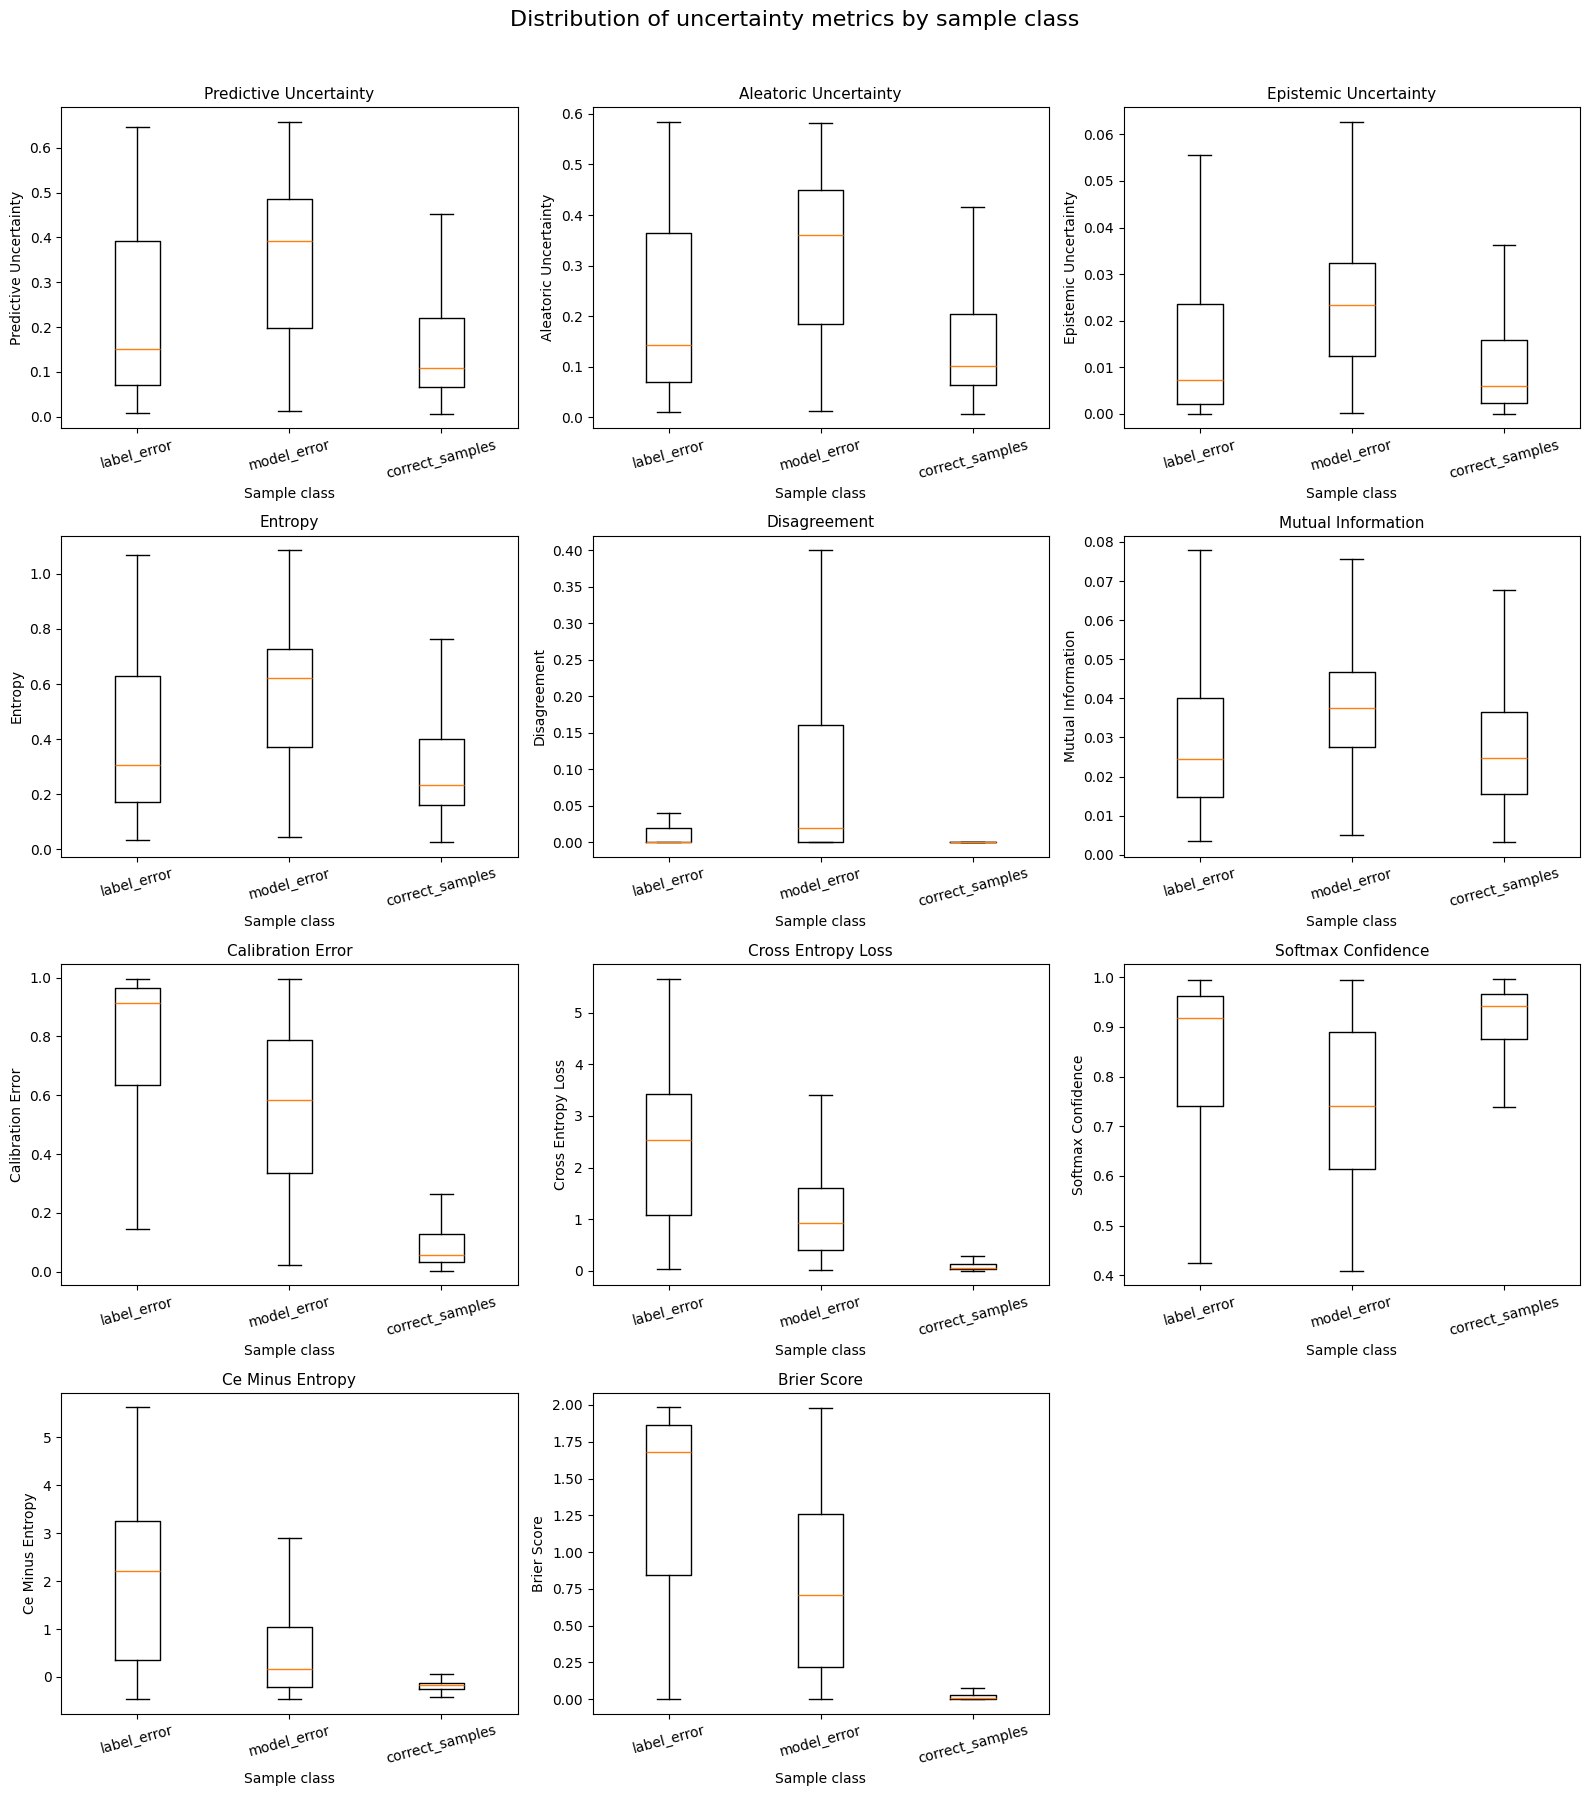

Saved combined boxplot figure to: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/figures/metric_boxplots/all_uncertainty_metric_boxplots.png


In [10]:
import math

n_cols = 3
n_rows = 4

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 18),
    sharex=False,
)

axes = axes.flatten()

for i, metric in enumerate(FEATURE_NAMES):

    data = [
        analysis_df.loc[
            analysis_df["class_name"] == class_name,
            metric,
        ].dropna().to_numpy()
        for class_name in class_order
    ]

    ax = axes[i]

    ax.boxplot(
        data,
        labels=class_order,
        showfliers=False,
    )

    ax.set_title(
        metric.replace("_", " ").title(),
        fontsize=11,
    )

    ax.set_xlabel("Sample class")
    ax.set_ylabel(metric.replace("_", " ").title())

    ax.tick_params(
        axis="x",
        rotation=15,
    )

# Remove unused subplot axes
for ax in axes[len(FEATURE_NAMES):]:
    fig.delaxes(ax)

fig.suptitle(
    "Distribution of uncertainty metrics by sample class",
    fontsize=16,
    y=0.995,
)

fig.tight_layout(rect=[0, 0, 1, 0.98])

output_path = BOXPLOT_DIR / "all_uncertainty_metric_boxplots.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print(f"Saved combined boxplot figure to: {output_path}")

## RQ1 — Kruskal–Wallis and pairwise Mann–Whitney U tests

In [11]:
def holm_adjust(p_values):
    """Return Holm-adjusted p-values in the original order."""
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)
    order = np.argsort(p_values)
    adjusted_sorted = np.empty(n, dtype=float)
    running_max = 0.0

    for rank, idx in enumerate(order):
        adjusted = (n - rank) * p_values[idx]
        running_max = max(running_max, adjusted)
        adjusted_sorted[rank] = min(running_max, 1.0)

    adjusted = np.empty(n, dtype=float)
    for rank, idx in enumerate(order):
        adjusted[idx] = adjusted_sorted[rank]
    return adjusted


kruskal_rows = []
pairwise_rows = []

for metric in FEATURE_NAMES:
    grouped_values = {
        class_name: analysis_df.loc[
            analysis_df["class_name"] == class_name,
            metric,
        ].dropna().astype(float).to_numpy()
        for class_name in class_order
    }

    h_statistic, p_value = kruskal(
        *(grouped_values[class_name] for class_name in class_order)
    )
    kruskal_rows.append({
        "metric": metric,
        "h_statistic": float(h_statistic),
        "p_value": float(p_value),
        "significant_at_0_05": bool(p_value < 0.05),
    })

    metric_pair_rows = []
    for class_a, class_b in combinations(class_order, 2):
        values_a = grouped_values[class_a]
        values_b = grouped_values[class_b]
        u_statistic, raw_p = mannwhitneyu(
            values_a,
            values_b,
            alternative="two-sided",
        )

        n_a = len(values_a)
        n_b = len(values_b)
        rank_biserial = (
            2.0 * float(u_statistic) / float(n_a * n_b) - 1.0
        )

        metric_pair_rows.append({
            "metric": metric,
            "class_a": class_a,
            "class_b": class_b,
            "n_a": int(n_a),
            "n_b": int(n_b),
            "u_statistic": float(u_statistic),
            "p_value_raw": float(raw_p),
            "rank_biserial_a_greater_than_b": float(rank_biserial),
        })

    adjusted = holm_adjust(
        [row["p_value_raw"] for row in metric_pair_rows]
    )
    for row, adjusted_p in zip(metric_pair_rows, adjusted):
        row["p_value_holm"] = float(adjusted_p)
        row["significant_at_0_05_holm"] = bool(adjusted_p < 0.05)
        pairwise_rows.append(row)

kruskal_results = pd.DataFrame(kruskal_rows).sort_values(
    "p_value",
    ascending=True,
).reset_index(drop=True)

pairwise_results = pd.DataFrame(pairwise_rows).sort_values(
    ["metric", "p_value_holm"],
    ascending=[True, True],
).reset_index(drop=True)

kruskal_results.to_csv(KRUSKAL_WALLIS_CSV, index=False)
pairwise_results.to_csv(PAIRWISE_MANN_WHITNEY_CSV, index=False)

print("Kruskal–Wallis results:")
display(kruskal_results)

print("Pairwise Mann–Whitney U results with Holm correction:")
display(pairwise_results)

print(f"Saved: {KRUSKAL_WALLIS_CSV}")
print(f"Saved: {PAIRWISE_MANN_WHITNEY_CSV}")

Kruskal–Wallis results:


,metric,h_statistic,p_value,significant_at_0_05
0,predictive_uncertainty,192732.567681,0.0,True
1,aleatoric_uncertainty,191540.813886,0.0,True
2,epistemic_uncertainty,161213.870091,0.0,True
3,entropy,191268.194184,0.0,True
4,disagreement,162456.342901,0.0,True
5,mutual_information,89032.714529,0.0,True
6,calibration_error,629578.643480,0.0,True
7,cross_entropy_loss,630454.089432,0.0,True
8,softmax_confidence,193773.228525,0.0,True
9,ce_minus_entropy,340009.088230,0.0,True


Pairwise Mann–Whitney U results with Holm correction:


,metric,class_a,class_b,n_a,n_b,u_statistic,p_value_raw,rank_biserial_a_greater_than_b,p_value_holm,significant_at_0_05_holm
0,aleatoric_uncertainty,label_error,model_error,351862,351862,3.775191e+10,0.000000e+00,-0.390148,0.000000e+00,True
1,aleatoric_uncertainty,label_error,correct_samples,351862,351862,7.316046e+10,0.000000e+00,0.181848,0.000000e+00,True
2,aleatoric_uncertainty,model_error,correct_samples,351862,351862,9.901094e+10,0.000000e+00,0.599442,0.000000e+00,True
3,brier_score,label_error,model_error,351862,351862,9.135912e+10,0.000000e+00,0.475833,0.000000e+00,True
4,brier_score,label_error,correct_samples,351862,351862,1.207033e+11,0.000000e+00,0.949864,0.000000e+00,True
5,brier_score,model_error,correct_samples,351862,351862,1.139268e+11,0.000000e+00,0.840395,0.000000e+00,True
6,calibration_error,label_error,model_error,351862,351862,9.119565e+10,0.000000e+00,0.473192,0.000000e+00,True
7,calibration_error,label_error,correct_samples,351862,351862,1.207088e+11,0.000000e+00,0.949954,0.000000e+00,True
8,calibration_error,model_error,correct_samples,351862,351862,1.139598e+11,0.000000e+00,0.840929,0.000000e+00,True
9,ce_minus_entropy,label_error,model_error,351862,351862,9.019727e+10,0.000000e+00,0.457064,0.000000e+00,True


Saved: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/metric_kruskal_wallis_tests.csv
Saved: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/metric_pairwise_mann_whitney_holm.csv


## Cell 8 — Train the Decision Tree

In [12]:
FEATURE_NAMES = list(METRIC_PATHS)

training_df = pixels_balanced[
    ["class_name", "polygon_group", *FEATURE_NAMES]
].copy()

training_df = training_df.replace(
    [np.inf, -np.inf],
    np.nan,
).dropna(subset=FEATURE_NAMES)

X = training_df[FEATURE_NAMES].to_numpy(dtype="float32")
y = (
    training_df["class_name"]
    .map(CLASS_TO_CODE)
    .to_numpy(dtype="uint8")
)

decision_tree = DecisionTreeClassifier(
    max_depth=DECISION_TREE_MAX_DEPTH,
    min_samples_leaf=MIN_SAMPLES_LEAF,
    class_weight=CLASS_WEIGHT,
    random_state=RANDOM_SEED,
)

decision_tree.fit(X, y)

training_predictions = decision_tree.predict(X)
training_accuracy = float(
    np.mean(training_predictions == y)
)

print(f"Training rows: {len(training_df):,}")
print(f"Training accuracy: {training_accuracy:.4f}")
print(f"Tree depth: {decision_tree.get_depth()}")
print(f"Leaf nodes: {decision_tree.get_n_leaves()}")

joblib.dump(decision_tree, DT_MODEL_PATH)
print(f"Saved model: {DT_MODEL_PATH}")

Training rows: 1,055,586
Training accuracy: 0.7166
Tree depth: 5
Leaf nodes: 32
Saved model: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/models/decision_tree_model.joblib


## RQ2 — Decision Tree feature importance

,metric,importance,rank
0,brier_score,0.625882,1
1,epistemic_uncertainty,0.235739,2
2,ce_minus_entropy,0.063814,3
3,mutual_information,0.031741,4
4,disagreement,0.024148,5
5,entropy,0.013997,6
6,aleatoric_uncertainty,0.002995,7
7,cross_entropy_loss,0.001683,8
8,predictive_uncertainty,0.000000,9
9,calibration_error,0.000000,10


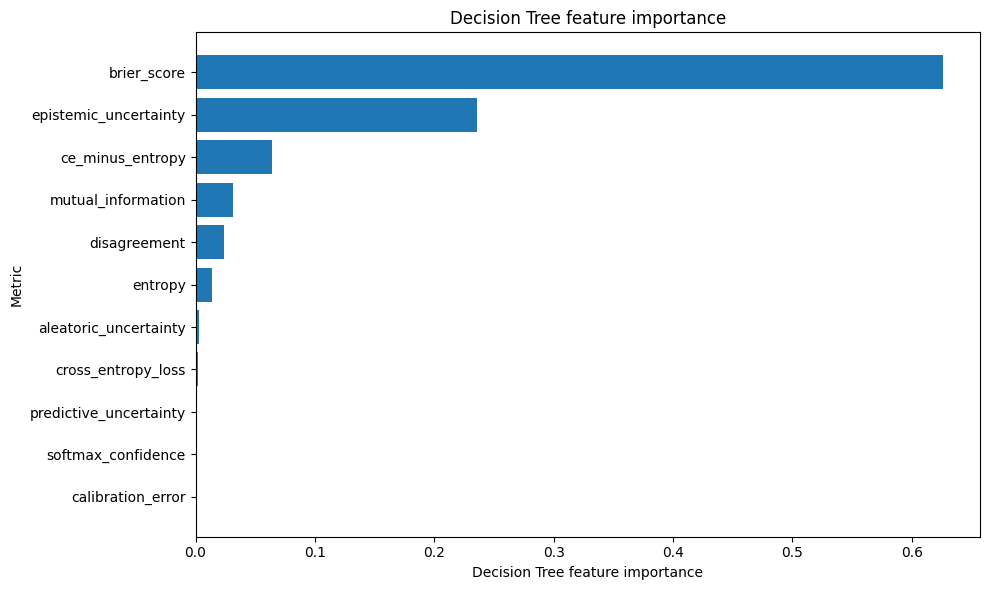

Saved table: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/decision_tree_feature_importance.csv
Saved figure: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/figures/decision_tree_feature_importance.png


In [13]:
dt_feature_importance = pd.DataFrame({
    "metric": FEATURE_NAMES,
    "importance": decision_tree.feature_importances_,
}).sort_values(
    "importance",
    ascending=False,
).reset_index(drop=True)

dt_feature_importance["rank"] = np.arange(
    1,
    len(dt_feature_importance) + 1,
)

dt_feature_importance.to_csv(
    DT_FEATURE_IMPORTANCE_CSV,
    index=False,
)
display(dt_feature_importance)

plot_df = dt_feature_importance.sort_values(
    "importance",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_df["metric"], plot_df["importance"])
ax.set_xlabel("Decision Tree feature importance")
ax.set_ylabel("Metric")
ax.set_title("Decision Tree feature importance")
fig.tight_layout()
fig.savefig(
    DT_FEATURE_IMPORTANCE_PNG,
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print(f"Saved table: {DT_FEATURE_IMPORTANCE_CSV}")
print(f"Saved figure: {DT_FEATURE_IMPORTANCE_PNG}")

## RQ2 — Train memory-optimised Random Forest (500 trees)

In [14]:
# Fit a 500-tree RF on a reproducible, class-balanced subset to bound RAM use.
# The full pixel dataset remains available for the Decision Tree and other analyses.
import gc

rf_rng = np.random.default_rng(RANDOM_SEED)
rf_selected = []

for class_code in sorted(np.unique(y)):
    class_indices = np.flatnonzero(y == class_code)
    n_take = min(len(class_indices), RF_MAX_PIXELS_PER_CLASS)
    rf_selected.append(
        rf_rng.choice(class_indices, size=n_take, replace=False)
    )

rf_indices = np.concatenate(rf_selected)
rf_rng.shuffle(rf_indices)

X_rf = np.ascontiguousarray(X[rf_indices], dtype=np.float32)
y_rf = np.ascontiguousarray(y[rf_indices], dtype=np.uint8)
del rf_indices, rf_selected
gc.collect()

print(f"RF training samples: {len(y_rf):,} (full training set: {len(y):,})")
print("Samples by class:", {
    CODE_TO_CLASS[int(code)]: int((y_rf == code).sum())
    for code in np.unique(y_rf)
})
print(f"RF trees: {RF_N_ESTIMATORS}, parallel jobs: {RF_N_JOBS}")

random_forest = RandomForestClassifier(
    n_estimators=RF_N_ESTIMATORS,
    class_weight=CLASS_WEIGHT,
    random_state=RANDOM_SEED,
    n_jobs=RF_N_JOBS,
    oob_score=True,
    bootstrap=True,
    max_samples=RF_MAX_SAMPLES,
    max_depth=RF_MAX_DEPTH,
    min_samples_leaf=RF_MIN_SAMPLES_LEAF,
)

random_forest.fit(X_rf, y_rf)

# Predict only the RF training subset, not the entire full-resolution pixel table.
rf_training_accuracy = float(
    np.mean(random_forest.predict(X_rf) == y_rf)
)

print(f"Random Forest trees: {RF_N_ESTIMATORS}")
print(f"Training accuracy (RF subset): {rf_training_accuracy:.4f}")
print(f"Out-of-bag score (RF subset): {random_forest.oob_score_:.4f}")

joblib.dump(random_forest, RF_MODEL_PATH, compress=3)

rf_metadata = {
    "experiment_name": EXPERIMENT_NAME,
    "n_estimators": RF_N_ESTIMATORS,
    "feature_names": FEATURE_NAMES,
    "class_to_code": CLASS_TO_CODE,
    "full_training_rows": int(len(training_df)),
    "training_rows": int(len(y_rf)),
    "max_pixels_per_class": RF_MAX_PIXELS_PER_CLASS,
    "n_jobs": RF_N_JOBS,
    "max_depth": RF_MAX_DEPTH,
    "min_samples_leaf": RF_MIN_SAMPLES_LEAF,
    "max_samples": RF_MAX_SAMPLES,
    "training_accuracy": rf_training_accuracy,
    "oob_score": float(random_forest.oob_score_),
    "random_seed": RANDOM_SEED,
}
RF_METADATA_JSON.write_text(
    json.dumps(rf_metadata, indent=2),
    encoding="utf-8",
)

# Release the temporary subset; the fitted forest stays available for feature importance.
del X_rf, y_rf
gc.collect()

print(f"Saved model: {RF_MODEL_PATH}")
print(f"Saved metadata: {RF_METADATA_JSON}")


RF training samples: 60,000 (full training set: 1,055,586)
Samples by class: {'label_error': 20000, 'model_error': 20000, 'correct_samples': 20000}
RF trees: 500, parallel jobs: 2
Random Forest trees: 500
Training accuracy (RF subset): 0.8436
Out-of-bag score (RF subset): 0.7604
Saved model: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/models/random_forest_500_trees.joblib
Saved metadata: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/random_forest_metadata.json


## RQ2 — Random Forest feature importance

,metric,importance,rank
0,brier_score,0.185392,1
1,cross_entropy_loss,0.163504,2
2,calibration_error,0.138102,3
3,ce_minus_entropy,0.130212,4
4,epistemic_uncertainty,0.091578,5
5,mutual_information,0.075746,6
6,entropy,0.056996,7
7,softmax_confidence,0.046888,8
8,predictive_uncertainty,0.046051,9
9,aleatoric_uncertainty,0.044110,10


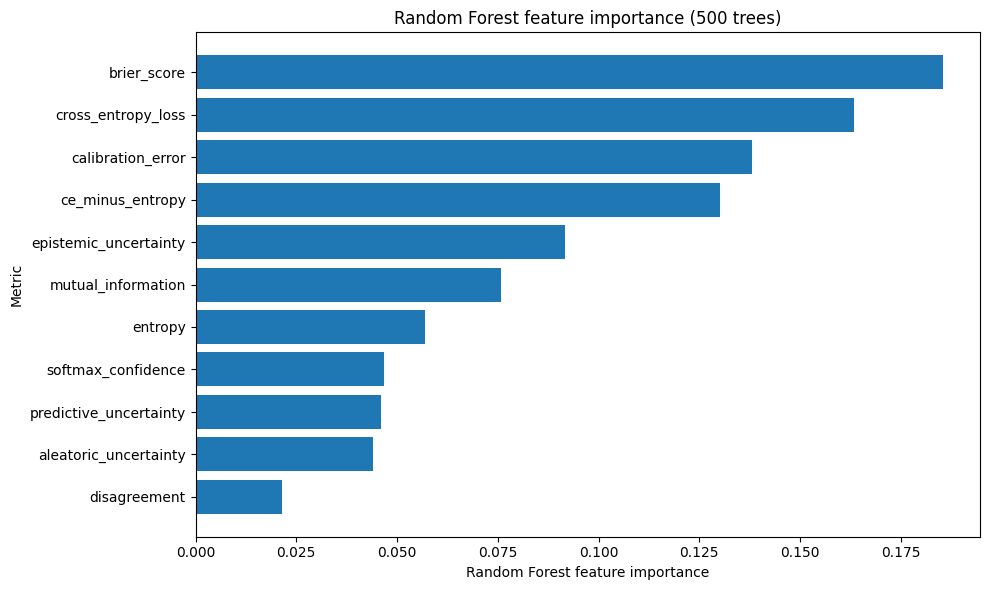

Saved table: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/random_forest_feature_importance.csv
Saved figure: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/figures/random_forest_feature_importance.png


In [15]:
rf_feature_importance = pd.DataFrame({
    "metric": FEATURE_NAMES,
    "importance": random_forest.feature_importances_,
}).sort_values(
    "importance",
    ascending=False,
).reset_index(drop=True)

rf_feature_importance["rank"] = np.arange(
    1,
    len(rf_feature_importance) + 1,
)

rf_feature_importance.to_csv(
    RF_FEATURE_IMPORTANCE_CSV,
    index=False,
)
display(rf_feature_importance)

plot_df = rf_feature_importance.sort_values(
    "importance",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_df["metric"], plot_df["importance"])
ax.set_xlabel("Random Forest feature importance")
ax.set_ylabel("Metric")
ax.set_title("Random Forest feature importance (500 trees)")
fig.tight_layout()
fig.savefig(
    RF_FEATURE_IMPORTANCE_PNG,
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print(f"Saved table: {RF_FEATURE_IMPORTANCE_CSV}")
print(f"Saved figure: {RF_FEATURE_IMPORTANCE_PNG}")

## RQ2 — HSIC helper functions and balanced subset

In [16]:
def centred_kernel(kernel):
    """Double-centre a square kernel matrix."""
    row_mean = kernel.mean(axis=1, keepdims=True)
    column_mean = kernel.mean(axis=0, keepdims=True)
    grand_mean = kernel.mean()
    return kernel - row_mean - column_mean + grand_mean


def median_heuristic_gamma(values):
    """RBF gamma from the median non-zero pairwise squared distance."""
    values = np.asarray(values, dtype=np.float64).reshape(-1, 1)
    squared_distances = (
        values ** 2
        + (values ** 2).T
        - 2.0 * values @ values.T
    )
    squared_distances = np.maximum(squared_distances, 0.0)
    upper = squared_distances[np.triu_indices_from(
        squared_distances,
        k=1,
    )]
    positive = upper[upper > 0]

    if positive.size == 0:
        return 1.0

    median_squared_distance = float(np.median(positive))
    return 1.0 / (2.0 * median_squared_distance)


def normalised_hsic(feature_values, labels):
    """
    Compute a normalised biased HSIC score.

    The predictor uses an RBF kernel with a median-heuristic gamma.
    The class variable uses a delta kernel. The normalised score is
    comparable across metrics and lies close to the [0, 1] range.
    """
    x = np.asarray(feature_values, dtype=np.float64).reshape(-1, 1)
    labels = np.asarray(labels)

    gamma = median_heuristic_gamma(x)
    k = rbf_kernel(x, x, gamma=gamma)
    l = (labels[:, None] == labels[None, :]).astype(np.float64)

    kc = centred_kernel(k)
    lc = centred_kernel(l)

    numerator = float(np.sum(kc * lc))
    denominator = float(
        np.sqrt(np.sum(kc * kc) * np.sum(lc * lc))
    )

    score = numerator / denominator if denominator > 0 else np.nan
    return score, gamma


hsic_parts = []
for class_name in class_order:
    subset = analysis_df[
        analysis_df["class_name"] == class_name
    ]
    n_take = min(
        len(subset),
        HSIC_MAX_SAMPLES_PER_CLASS,
    )
    hsic_parts.append(
        subset.sample(
            n=n_take,
            random_state=RANDOM_SEED,
            replace=False,
        )
    )

hsic_df = pd.concat(
    hsic_parts,
    ignore_index=True,
).sample(
    frac=1.0,
    random_state=RANDOM_SEED,
).reset_index(drop=True)

print("Balanced HSIC subset:")
display(
    hsic_df["class_name"]
    .value_counts()
    .rename_axis("class_name")
    .reset_index(name="n_samples")
)
print(f"Total HSIC rows: {len(hsic_df):,}")

Balanced HSIC subset:


,class_name,n_samples
0,correct_samples,500
1,label_error,500
2,model_error,500


Total HSIC rows: 1,500


## RQ2 — Overall three-class and one-vs-rest HSIC scores

In [17]:
overall_hsic_rows = []
one_vs_rest_hsic_rows = []

multiclass_labels = hsic_df["class_name"].to_numpy()

for metric in FEATURE_NAMES:
    values = hsic_df[metric].astype(float).to_numpy()

    overall_score, gamma = normalised_hsic(
        values,
        multiclass_labels,
    )
    overall_hsic_rows.append({
        "metric": metric,
        "comparison": "overall_three_class",
        "hsic_score": float(overall_score),
        "rbf_gamma": float(gamma),
        "n_samples": int(len(hsic_df)),
    })

    for class_name in class_order:
        binary_membership = (
            hsic_df["class_name"].to_numpy() == class_name
        ).astype(np.uint8)

        class_score, class_gamma = normalised_hsic(
            values,
            binary_membership,
        )
        one_vs_rest_hsic_rows.append({
            "metric": metric,
            "class_name": class_name,
            "comparison": f"{class_name}_vs_rest",
            "hsic_score": float(class_score),
            "rbf_gamma": float(class_gamma),
            "n_samples": int(len(hsic_df)),
        })

hsic_overall = pd.DataFrame(overall_hsic_rows).sort_values(
    "hsic_score",
    ascending=False,
).reset_index(drop=True)
hsic_overall["rank"] = np.arange(1, len(hsic_overall) + 1)

hsic_one_vs_rest = pd.DataFrame(one_vs_rest_hsic_rows)
hsic_one_vs_rest["rank_within_class"] = (
    hsic_one_vs_rest.groupby("class_name")["hsic_score"]
    .rank(method="dense", ascending=False)
    .astype(int)
)
hsic_one_vs_rest = hsic_one_vs_rest.sort_values(
    ["class_name", "rank_within_class", "metric"]
).reset_index(drop=True)

hsic_combined = pd.concat(
    [
        hsic_overall.assign(class_name="all_classes"),
        hsic_one_vs_rest,
    ],
    ignore_index=True,
    sort=False,
)

hsic_overall.to_csv(HSIC_OVERALL_CSV, index=False)
hsic_one_vs_rest.to_csv(HSIC_ONE_VS_REST_CSV, index=False)
hsic_combined.to_csv(HSIC_COMBINED_CSV, index=False)

print("Overall three-class HSIC ranking:")
display(hsic_overall)

print("One-vs-rest HSIC ranking for each class:")
display(hsic_one_vs_rest)

print(f"Saved: {HSIC_OVERALL_CSV}")
print(f"Saved: {HSIC_ONE_VS_REST_CSV}")
print(f"Saved: {HSIC_COMBINED_CSV}")

Overall three-class HSIC ranking:


,metric,comparison,hsic_score,rbf_gamma,n_samples,rank
0,calibration_error,overall_three_class,0.416229,3.607192,1500,1
1,brier_score,overall_three_class,0.359842,0.981786,1500,2
2,cross_entropy_loss,overall_three_class,0.334609,0.417994,1500,3
3,ce_minus_entropy,overall_three_class,0.270930,0.513045,1500,4
4,predictive_uncertainty,overall_three_class,0.097943,17.832872,1500,5
5,entropy,overall_three_class,0.097436,9.096222,1500,6
6,aleatoric_uncertainty,overall_three_class,0.097336,20.810393,1500,7
7,softmax_confidence,overall_three_class,0.095426,29.007779,1500,8
8,epistemic_uncertainty,overall_three_class,0.080164,2858.266973,1500,9
9,disagreement,overall_three_class,0.073228,34.722224,1500,10


One-vs-rest HSIC ranking for each class:


,metric,class_name,comparison,hsic_score,rbf_gamma,n_samples,rank_within_class
0,calibration_error,correct_samples,correct_samples_vs_rest,0.524921,3.607192,1500,1
1,brier_score,correct_samples,correct_samples_vs_rest,0.418979,0.981786,1500,2
2,cross_entropy_loss,correct_samples,correct_samples_vs_rest,0.365499,0.417994,1500,3
3,ce_minus_entropy,correct_samples,correct_samples_vs_rest,0.271527,0.513045,1500,4
4,predictive_uncertainty,correct_samples,correct_samples_vs_rest,0.082072,17.832872,1500,5
5,aleatoric_uncertainty,correct_samples,correct_samples_vs_rest,0.081851,20.810393,1500,6
6,softmax_confidence,correct_samples,correct_samples_vs_rest,0.081327,29.007779,1500,7
7,entropy,correct_samples,correct_samples_vs_rest,0.081175,9.096222,1500,8
8,disagreement,correct_samples,correct_samples_vs_rest,0.056297,34.722224,1500,9
9,epistemic_uncertainty,correct_samples,correct_samples_vs_rest,0.054737,2858.266973,1500,10


Saved: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/hsic_overall_three_class_scores.csv
Saved: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/hsic_one_vs_rest_scores.csv
Saved: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/hsic_all_scores.csv


## RQ2 — HSIC figures

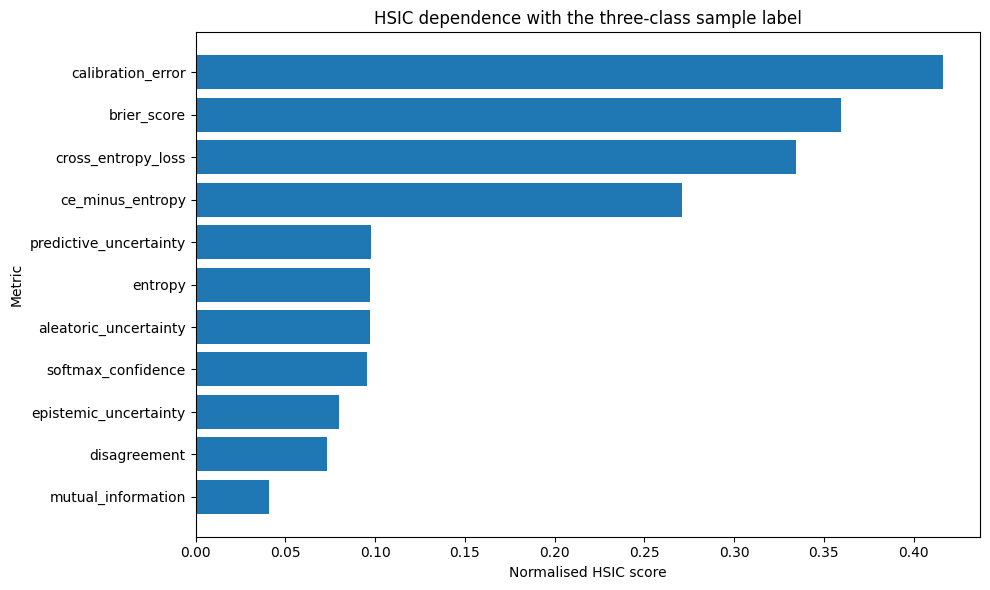

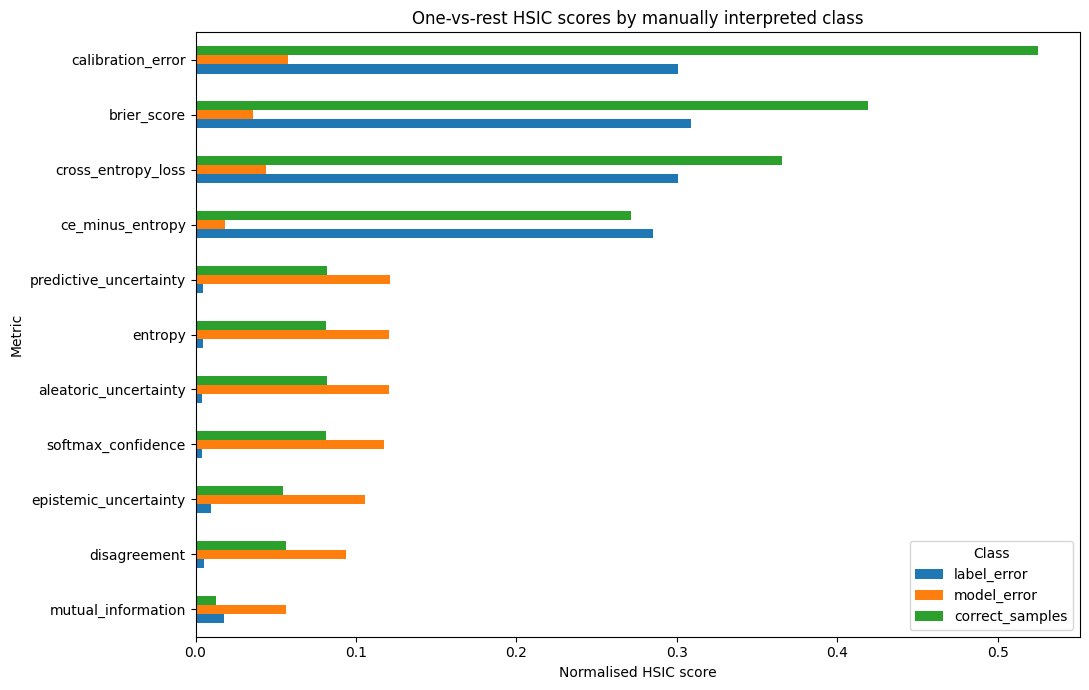

Saved figure: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/figures/hsic_overall_three_class_scores.png
Saved figure: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/figures/hsic_one_vs_rest_scores.png


In [18]:
overall_plot = hsic_overall.sort_values(
    "hsic_score",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(overall_plot["metric"], overall_plot["hsic_score"])
ax.set_xlabel("Normalised HSIC score")
ax.set_ylabel("Metric")
ax.set_title("HSIC dependence with the three-class sample label")
fig.tight_layout()
fig.savefig(
    HSIC_OVERALL_PNG,
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

pivot = hsic_one_vs_rest.pivot(
    index="metric",
    columns="class_name",
    values="hsic_score",
).reindex(columns=class_order)

pivot = pivot.loc[
    pivot.mean(axis=1).sort_values(ascending=True).index
]

fig, ax = plt.subplots(figsize=(11, 7))
pivot.plot(
    kind="barh",
    ax=ax,
)
ax.set_xlabel("Normalised HSIC score")
ax.set_ylabel("Metric")
ax.set_title("One-vs-rest HSIC scores by manually interpreted class")
ax.legend(title="Class")
fig.tight_layout()
fig.savefig(
    HSIC_ONE_VS_REST_PNG,
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print(f"Saved figure: {HSIC_OVERALL_PNG}")
print(f"Saved figure: {HSIC_ONE_VS_REST_PNG}")

## RQ2 — Combined Decision Tree, Random Forest and HSIC importance

In [19]:
required_tables = {
    "dt_feature_importance": dt_feature_importance,
    "rf_feature_importance": rf_feature_importance,
    "hsic_overall": hsic_overall,
}

for table_name, table in required_tables.items():
    if not isinstance(table, pd.DataFrame):
        raise TypeError(
            f"{table_name} must be a pandas DataFrame."
        )

# ------------------------------------------------------------
# Prepare the Decision Tree results
# ------------------------------------------------------------

dt_comparison = (
    dt_feature_importance[
        ["metric", "importance", "rank"]
    ]
    .rename(
        columns={
            "importance": "dt_importance",
            "rank": "dt_rank",
        }
    )
)

# ------------------------------------------------------------
# Prepare the Random Forest results
# ------------------------------------------------------------

rf_comparison = (
    rf_feature_importance[
        ["metric", "importance", "rank"]
    ]
    .rename(
        columns={
            "importance": "rf_importance",
            "rank": "rf_rank",
        }
    )
)

# ------------------------------------------------------------
# Prepare the overall three-class HSIC results
# ------------------------------------------------------------

hsic_comparison = (
    hsic_overall[
        ["metric", "hsic_score", "rank"]
    ]
    .rename(
        columns={
            "rank": "hsic_rank",
        }
    )
)

# ------------------------------------------------------------
# Combine the three methods by metric name
# ------------------------------------------------------------

metric_importance_comparison = (
    dt_comparison
    .merge(
        rf_comparison,
        on="metric",
        how="outer",
        validate="one_to_one",
    )
    .merge(
        hsic_comparison,
        on="metric",
        how="outer",
        validate="one_to_one",
    )
)

# ------------------------------------------------------------
# Calculate one overall rank for presentation
#
# A lower mean rank indicates that the metric was ranked more
# highly and more consistently across the three methods.
# ------------------------------------------------------------

metric_importance_comparison["mean_rank"] = (
    metric_importance_comparison[
        [
            "dt_rank",
            "rf_rank",
            "hsic_rank",
        ]
    ]
    .mean(axis=1)
)

metric_importance_comparison = (
    metric_importance_comparison
    .sort_values(
        [
            "mean_rank",
            "dt_rank",
            "rf_rank",
            "hsic_rank",
            "metric",
        ],
        ascending=True,
    )
    .reset_index(drop=True)
)

metric_importance_comparison.insert(
    0,
    "overall_rank",
    np.arange(
        1,
        len(metric_importance_comparison) + 1,
    ),
)

# ------------------------------------------------------------
# Create a condensed thesis table
# ------------------------------------------------------------

metric_importance_thesis = (
    metric_importance_comparison[
        [
            "overall_rank",
            "metric",
            "dt_importance",
            "rf_importance",
            "hsic_score",
        ]
    ]
    .copy()
)

# Improve metric names for manuscript presentation
metric_display_names = {
    "predictive_uncertainty": "Predictive uncertainty",
    "aleatoric_uncertainty": "Aleatoric uncertainty",
    "epistemic_uncertainty": "Epistemic uncertainty",
    "entropy": "Predictive entropy",
    "disagreement": "MC disagreement",
    "mutual_information": "Mutual information",
    "calibration_error": "Calibration error",
    "cross_entropy_loss": "Cross-entropy loss",
    "softmax": "Softmax confidence",
    "ce_minus_entropy": "CE − entropy",
    "brier": "Brier score",
}

metric_importance_thesis["metric"] = (
    metric_importance_thesis["metric"]
    .map(metric_display_names)
    .fillna(
        metric_importance_thesis["metric"]
        .str.replace("_", " ", regex=False)
        .str.title()
    )
)

# Round values for manuscript readability
value_columns = [
    "dt_importance",
    "rf_importance",
    "hsic_score",
]

metric_importance_thesis[value_columns] = (
    metric_importance_thesis[value_columns]
    .round(4)
)

# Rename columns for display
metric_importance_thesis = (
    metric_importance_thesis.rename(
        columns={
            "overall_rank": "Average Rank",
            "metric": "Metric",
            "dt_importance": "DT",
            "rf_importance": "RF",
            "hsic_score": "HSIC",
        }
    )
)

# ------------------------------------------------------------
# Export and display
# ------------------------------------------------------------

METRIC_IMPORTANCE_COMPARISON_CSV = (
    TABLE_OUTPUT_DIR
    / "combined_metric_importance_comparison.csv"
)

metric_importance_thesis.to_csv(
    METRIC_IMPORTANCE_COMPARISON_CSV,
    index=False,
)

print(
    "Combined Decision Tree, Random Forest and HSIC results:"
)
display(
    metric_importance_thesis.style.format(
        {
            "DT": "{:.4f}",
            "RF": "{:.4f}",
            "HSIC": "{:.4f}",
        }
    )
)

print(
    "Saved combined metric-importance table: "
    f"{METRIC_IMPORTANCE_COMPARISON_CSV}"
)

Combined Decision Tree, Random Forest and HSIC results:


,Average Rank,Metric,DT,RF,HSIC
0,1,Brier Score,0.6259,0.1854,0.3598
1,2,CE − entropy,0.0638,0.1302,0.2709
2,3,Cross-entropy loss,0.0017,0.1635,0.3346
3,4,Calibration error,0.0000,0.1381,0.4162
4,5,Epistemic uncertainty,0.2357,0.0916,0.0802
5,6,Predictive entropy,0.0140,0.0570,0.0974
6,7,Mutual information,0.0317,0.0757,0.0409
7,8,Predictive uncertainty,0.0000,0.0461,0.0979
8,9,Aleatoric uncertainty,0.0030,0.0441,0.0973
9,10,MC disagreement,0.0241,0.0214,0.0732


Saved combined metric-importance table: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/combined_metric_importance_comparison.csv


## Cell 10 — Decision Tree diagram and text rules

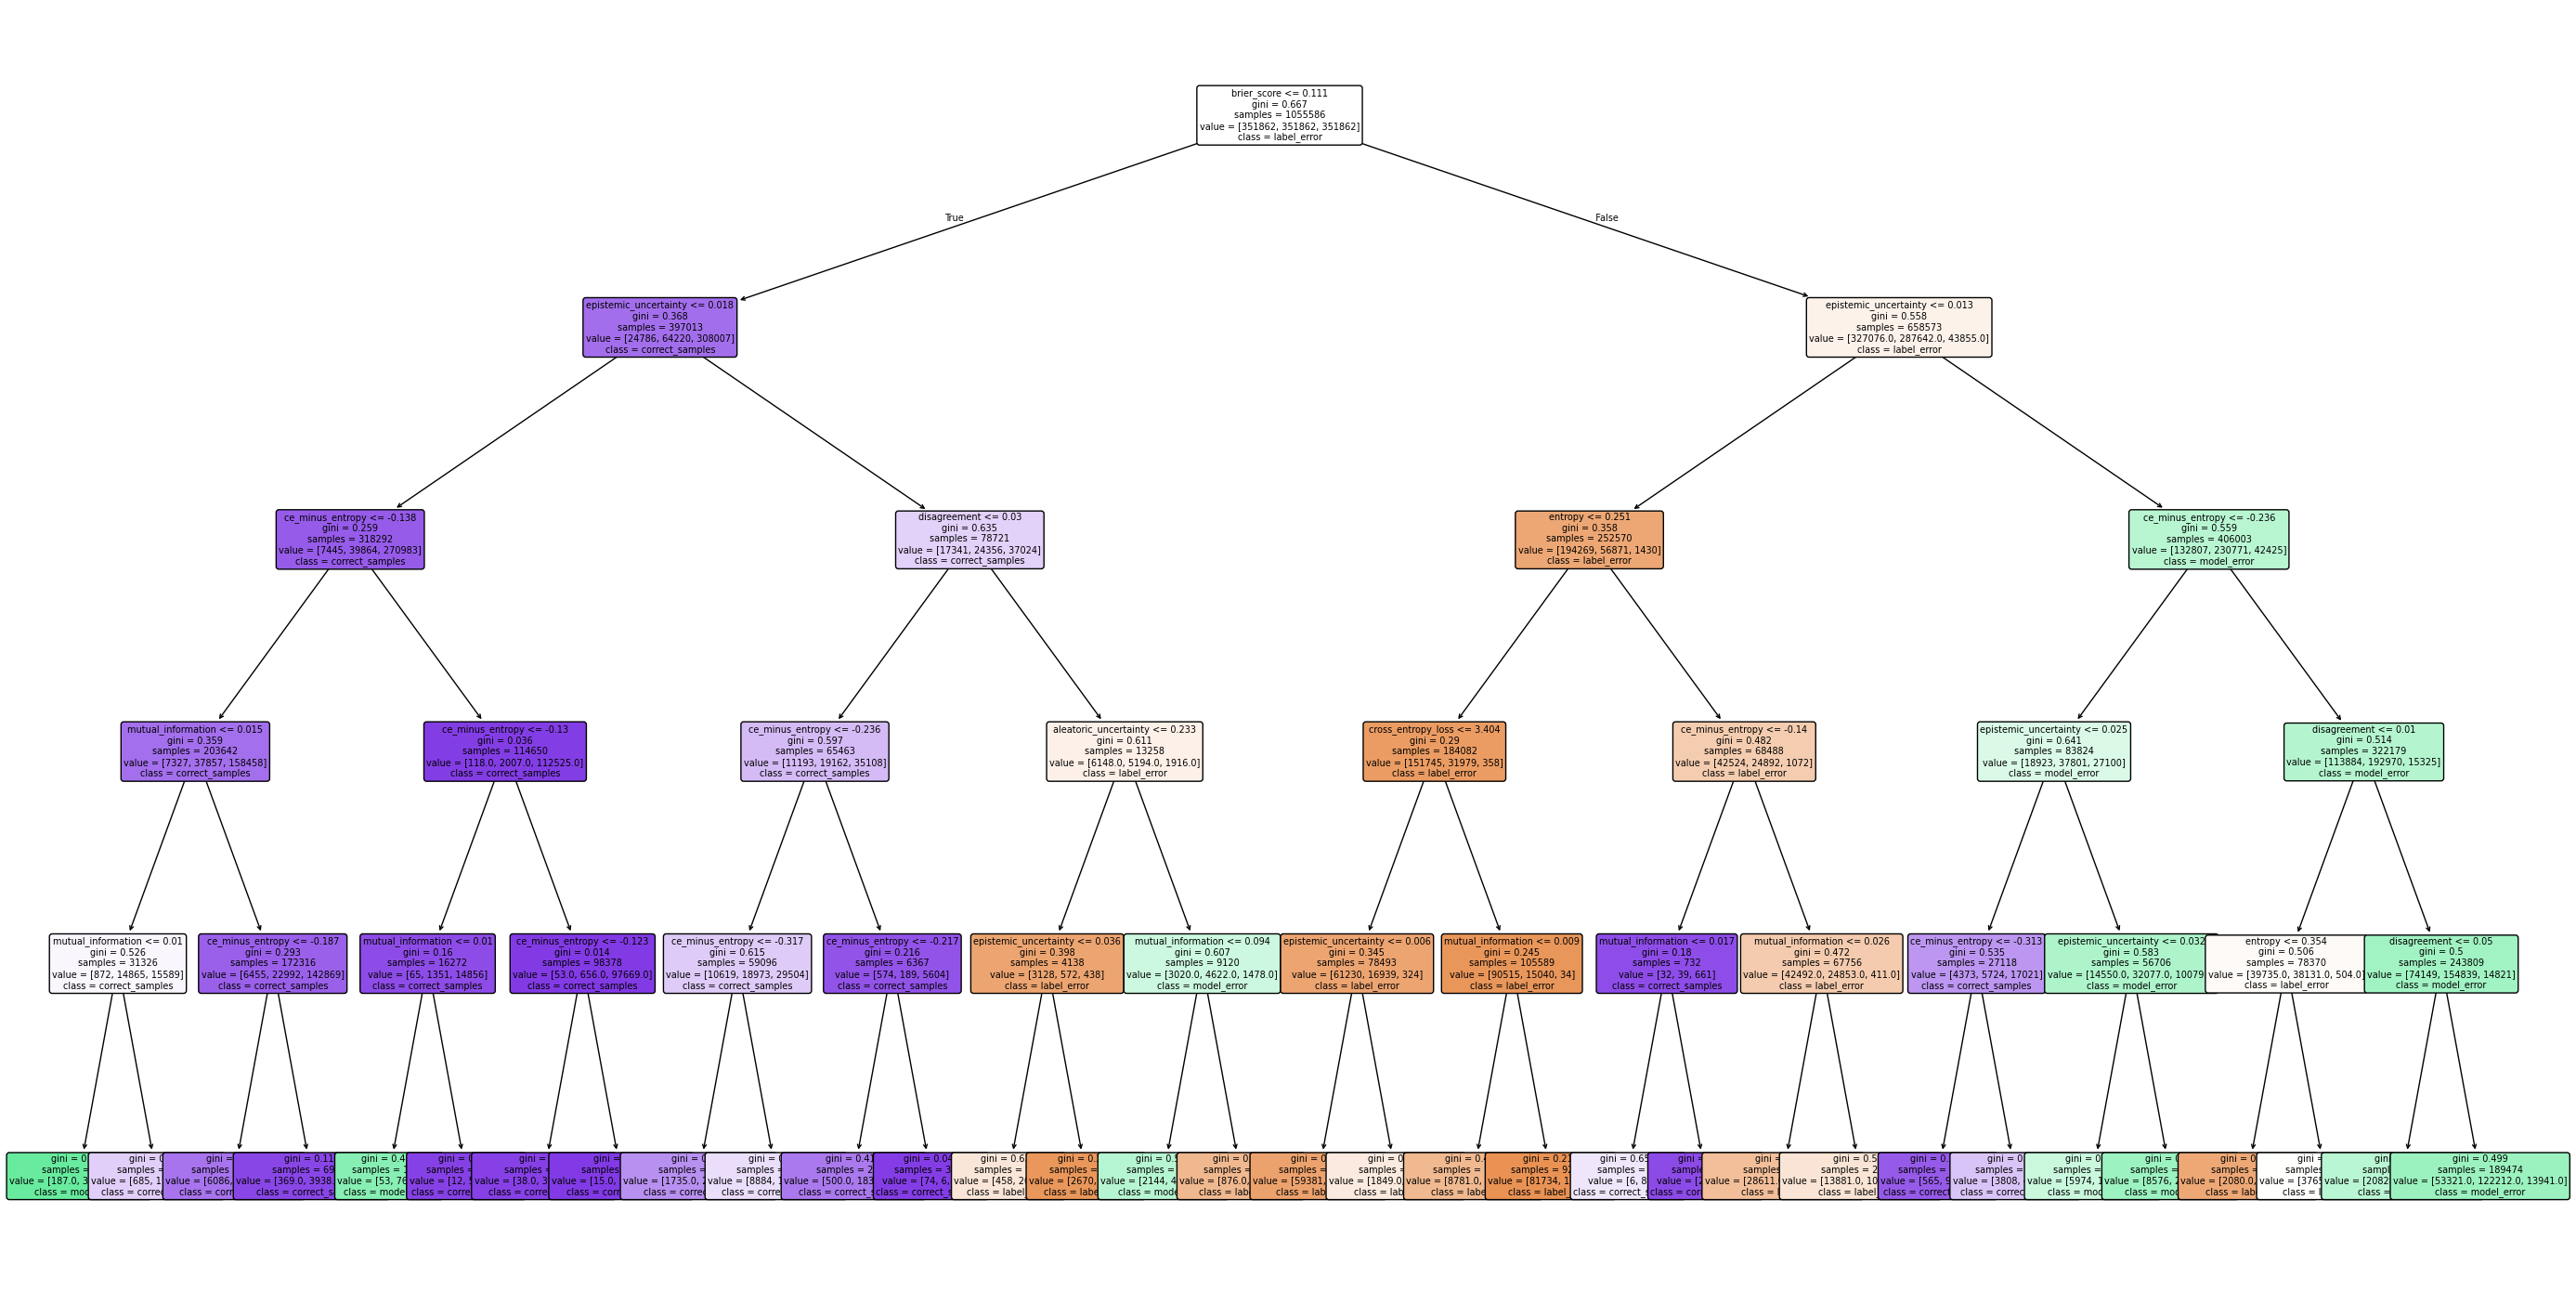

|--- brier_score <= 0.110786
|   |--- epistemic_uncertainty <= 0.017753
|   |   |--- ce_minus_entropy <= -0.138243
|   |   |   |--- mutual_information <= 0.014909
|   |   |   |   |--- mutual_information <= 0.010413
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- mutual_information >  0.010413
|   |   |   |   |   |--- class: 3
|   |   |   |--- mutual_information >  0.014909
|   |   |   |   |--- ce_minus_entropy <= -0.186865
|   |   |   |   |   |--- class: 3
|   |   |   |   |--- ce_minus_entropy >  -0.186865
|   |   |   |   |   |--- class: 3
|   |   |--- ce_minus_entropy >  -0.138243
|   |   |   |--- ce_minus_entropy <= -0.130076
|   |   |   |   |--- mutual_information <= 0.010011
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- mutual_information >  0.010011
|   |   |   |   |   |--- class: 3
|   |   |   |--- ce_minus_entropy >  -0.130076
|   |   |   |   |--- ce_minus_entropy <= -0.123426
|   |   |   |   |   |--- class: 3
|   |   |   |   |--- ce_minus_entropy >  -0.123426
| 

In [20]:
class_names_for_model = [
    CODE_TO_CLASS[int(code)]
    for code in decision_tree.classes_
]

plt.figure(figsize=(28, 14))
plot_tree(
    decision_tree,
    feature_names=FEATURE_NAMES,
    class_names=class_names_for_model,
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    fontsize=7,
)
plt.tight_layout()
plt.savefig(
    DT_DIAGRAM_PNG,
    dpi=250,
    bbox_inches="tight",
)
plt.show()

tree_rules = export_text(
    decision_tree,
    feature_names=FEATURE_NAMES,
    decimals=6,
    spacing=3,
)

rules_header = (
    "Decision Tree rules\n\n"
    "Class codes:\n"
    "1 = label_error\n"
    "2 = model_error\n"
    "3 = correct_samples\n\n"
)

DT_RULES_TXT.write_text(
    rules_header + tree_rules,
    encoding="utf-8",
)

print(tree_rules)
print(f"Saved diagram: {DT_DIAGRAM_PNG}")
print(f"Saved rules: {DT_RULES_TXT}")

## Cell 11 — Export Decision Tree class and label-error probability rasters

In [21]:
def predict_decision_tree_rasters(
    model,
    feature_names,
    metric_paths,
    class_output_path,
    label_error_probability_output_path,
    class_nodata_value=0,
    probability_nodata_value=-9999.0,
):
    """Export aligned hard-class and label-error probability rasters."""
    class_output_path = Path(class_output_path)
    label_error_probability_output_path = Path(
        label_error_probability_output_path
    )
    class_output_path.parent.mkdir(parents=True, exist_ok=True)
    label_error_probability_output_path.parent.mkdir(
        parents=True, exist_ok=True
    )

    matches = np.where(
        np.asarray(model.classes_) == CLASS_TO_CODE["label_error"]
    )[0]
    if len(matches) != 1:
        raise ValueError(
            "The Decision Tree does not contain exactly one label-error class."
        )
    label_error_index = int(matches[0])

    sources = [rasterio.open(metric_paths[name]) for name in feature_names]
    try:
        reference = sources[0]

        class_profile = reference.profile.copy()
        class_profile.update(
            count=1,
            dtype="uint8",
            nodata=class_nodata_value,
            compress="lzw",
            predictor=2,
            tiled=True,
        )

        probability_profile = reference.profile.copy()
        probability_profile.update(
            count=1,
            dtype="float32",
            nodata=float(probability_nodata_value),
            compress="lzw",
            predictor=3,
            tiled=True,
        )

        with rasterio.open(
            class_output_path, "w", **class_profile
        ) as class_destination:
            with rasterio.open(
                label_error_probability_output_path,
                "w",
                **probability_profile,
            ) as probability_destination:
                for _, window in reference.block_windows(1):
                    arrays = []
                    valid = None

                    for source in sources:
                        array = source.read(
                            1, window=window
                        ).astype("float32")
                        source_valid = np.isfinite(array)
                        if DROP_NODATA and source.nodata is not None:
                            source_valid &= array != float(source.nodata)
                        arrays.append(array)
                        valid = (
                            source_valid
                            if valid is None
                            else valid & source_valid
                        )

                    hard = np.full(
                        arrays[0].shape,
                        class_nodata_value,
                        dtype="uint8",
                    )
                    probability = np.full(
                        arrays[0].shape,
                        probability_nodata_value,
                        dtype="float32",
                    )

                    if valid.any():
                        X_window = np.column_stack(
                            [array[valid] for array in arrays]
                        ).astype("float32")
                        hard[valid] = model.predict(
                            X_window
                        ).astype("uint8")
                        probability[valid] = model.predict_proba(
                            X_window
                        )[:, label_error_index].astype("float32")

                    class_destination.write(hard, 1, window=window)
                    probability_destination.write(
                        probability, 1, window=window
                    )
    finally:
        for source in sources:
            source.close()

    return class_output_path, label_error_probability_output_path


prediction_path, label_error_probability_path = (
    predict_decision_tree_rasters(
        decision_tree,
        FEATURE_NAMES,
        METRIC_PATHS,
        DT_PREDICTION_RASTER,
        DT_LABEL_ERROR_PROBABILITY_RASTER,
    )
)

print(f"Saved Decision Tree prediction raster: {prediction_path}")
print(
    "Saved Decision Tree label-error probability raster: "
    f"{label_error_probability_path}"
)

Saved Decision Tree prediction raster: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/rasters/decision_tree_prediction.tif
Saved Decision Tree label-error probability raster: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/rasters/decision_tree_label_error_probability.tif


## Cell 12 — Export binary label-error masks for U-Net retraining

In [37]:

from contextlib import ExitStack


def export_label_error_masks(
    class_raster_path,
    probability_raster_path,
    original_mask_output_path,
    threshold_mask_outputs,
    mask_nodata_value=255,
):
    """
    Export the original Decision Tree mask and probability-threshold masks.

    Values in every output:
        1   = remove pixel as suspected label error
        0   = retain pixel for U-Net training
        255 = NoData

    The original mask uses the Decision Tree hard prediction.
    Threshold masks use P(label error) >= the selected threshold.

    Rasters are processed window by window to reduce RAM use.
    """

    class_raster_path = Path(class_raster_path)
    probability_raster_path = Path(probability_raster_path)
    original_mask_output_path = Path(original_mask_output_path)

    threshold_mask_outputs = {
        float(threshold): Path(output_path)
        for threshold, output_path in threshold_mask_outputs.items()
    }

    all_output_paths = [
        original_mask_output_path,
        *threshold_mask_outputs.values(),
    ]

    if len(set(all_output_paths)) != len(all_output_paths):
        raise ValueError("All mask output paths must be unique.")

    for threshold in threshold_mask_outputs:
        if not 0.0 <= threshold <= 1.0:
            raise ValueError(
                f"Probability threshold outside [0, 1]: {threshold}"
            )

    for output_path in all_output_paths:
        output_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

    removed_counts = {
        "original": 0,
        **{
            threshold: 0
            for threshold in threshold_mask_outputs
        },
    }

    valid_pixels = 0

    with rasterio.open(class_raster_path) as class_src, \
         rasterio.open(probability_raster_path) as probability_src:

        if (
            class_src.width != probability_src.width
            or class_src.height != probability_src.height
            or class_src.transform != probability_src.transform
            or class_src.crs != probability_src.crs
        ):
            raise ValueError(
                "Class and probability rasters are not spatially aligned."
            )

        profile = class_src.profile.copy()

        profile.update(
            count=1,
            dtype="uint8",
            nodata=int(mask_nodata_value),
            compress="lzw",
            predictor=2,
            tiled=True,
            blockxsize=256,
            blockysize=256,
        )

        with ExitStack() as stack:

            original_dst = stack.enter_context(
                rasterio.open(
                    original_mask_output_path,
                    "w",
                    **profile,
                )
            )

            threshold_dsts = {
                threshold: stack.enter_context(
                    rasterio.open(
                        output_path,
                        "w",
                        **profile,
                    )
                )
                for threshold, output_path
                in threshold_mask_outputs.items()
            }

            for _, window in class_src.block_windows(1):

                hard_class = class_src.read(
                    1,
                    window=window,
                )

                probability = probability_src.read(
                    1,
                    window=window,
                )

                valid = np.isfinite(probability)

                if class_src.nodata is not None:
                    valid &= hard_class != class_src.nodata

                if probability_src.nodata is not None:
                    valid &= probability != probability_src.nodata

                valid_pixels += int(valid.sum())

                # Original Decision Tree hard-class mask.
                original_mask = np.full(
                    hard_class.shape,
                    mask_nodata_value,
                    dtype="uint8",
                )

                original_mask[valid] = (
                    hard_class[valid]
                    == CLASS_TO_CODE["label_error"]
                ).astype("uint8")

                original_dst.write(
                    original_mask,
                    1,
                    window=window,
                )

                removed_counts["original"] += int(
                    np.sum(original_mask[valid] == 1)
                )

                # Probability-threshold masks.
                for threshold, dst in threshold_dsts.items():

                    threshold_mask = np.full(
                        hard_class.shape,
                        mask_nodata_value,
                        dtype="uint8",
                    )

                    threshold_mask[valid] = (
                        probability[valid] >= threshold
                    ).astype("uint8")

                    dst.write(
                        threshold_mask,
                        1,
                        window=window,
                    )

                    removed_counts[threshold] += int(
                        np.sum(threshold_mask[valid] == 1)
                    )

    # Build the four-mask summary table.
    summary_rows = [
        {
            "mask": "original_decision_tree_label_error",
            "criterion": "hard prediction == label_error",
            "removed_pixels": removed_counts["original"],
            "valid_pixels": valid_pixels,
            "removed_percent": (
                100.0 * removed_counts["original"] / valid_pixels
                if valid_pixels > 0
                else np.nan
            ),
            "output_path": str(original_mask_output_path),
        }
    ]

    for threshold, output_path in sorted(
        threshold_mask_outputs.items()
    ):

        removed_pixels = removed_counts[threshold]

        summary_rows.append({
            "mask": (
                f"label_error_probability_"
                f"{int(round(threshold * 100))}pct"
            ),
            "criterion": (
                f"P(label_error) >= {threshold:.2f}"
            ),
            "removed_pixels": removed_pixels,
            "valid_pixels": valid_pixels,
            "removed_percent": (
                100.0 * removed_pixels / valid_pixels
                if valid_pixels > 0
                else np.nan
            ),
            "output_path": str(output_path),
        })

    return pd.DataFrame(summary_rows)


# Export the original, 35%, 55%, and 85% masks.
label_error_mask_summary = export_label_error_masks(
    class_raster_path=DT_PREDICTION_RASTER,
    probability_raster_path=DT_LABEL_ERROR_PROBABILITY_RASTER,
    original_mask_output_path=DT_ORIGINAL_LABEL_ERROR_MASK_RASTER,
    threshold_mask_outputs={
        LABEL_ERROR_PROBABILITY_THRESHOLD_35:
            DT_LABEL_ERROR_35_MASK_RASTER,
        LABEL_ERROR_PROBABILITY_THRESHOLD_55:
            DT_LABEL_ERROR_55_MASK_RASTER,
        LABEL_ERROR_PROBABILITY_THRESHOLD_85:
            DT_LABEL_ERROR_85_MASK_RASTER,
    },
    mask_nodata_value=LABEL_ERROR_MASK_NODATA,
)

display(
    label_error_mask_summary.style.format({
        "removed_percent": "{:.4f}%",
    })
)

print("\nExported label-error masks:")

for output_path in [
    DT_ORIGINAL_LABEL_ERROR_MASK_RASTER,
    DT_LABEL_ERROR_35_MASK_RASTER,
    DT_LABEL_ERROR_55_MASK_RASTER,
    DT_LABEL_ERROR_85_MASK_RASTER,
]:
    print(f"Saved mask: {output_path}")

print(
    "\nMask coding: "
    "1 = remove as suspected label error, "
    "0 = retain for training, "
    "255 = NoData."
)

# Save the completed masks to persistent Google Drive storage.
sync_outputs_to_drive()

,mask,criterion,removed_pixels,valid_pixels,removed_percent,output_path
0,original_decision_tree_label_error,hard prediction == label_error,5735410,192790240,2.9749%,/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/label_error_masks/decision_tree_original_label_error_mask.tif
1,label_error_probability_35pct,P(label_error) >= 0.35,7546808,192790240,3.9145%,/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/label_error_masks/decision_tree_label_error_probability_35pct_mask.tif
2,label_error_probability_55pct,P(label_error) >= 0.55,3405076,192790240,1.7662%,/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/label_error_masks/decision_tree_label_error_probability_55pct_mask.tif
3,label_error_probability_85pct,P(label_error) >= 0.85,682505,192790240,0.3540%,/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/label_error_masks/decision_tree_label_error_probability_85pct_mask.tif



Exported label-error masks:
Saved mask: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/label_error_masks/decision_tree_original_label_error_mask.tif
Saved mask: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/label_error_masks/decision_tree_label_error_probability_35pct_mask.tif
Saved mask: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/label_error_masks/decision_tree_label_error_probability_55pct_mask.tif
Saved mask: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/label_error_masks/decision_tree_label_error_probability_85pct_mask.tif

Mask coding: 1 = remove as suspected label error, 0 = retain for training, 255 = NoData.
Synced 42 files to ../outputs/dt_rf500_hsic_rq_analysis_v1


## Cell 13 — Export validation points from DT-predicted classes

In [25]:
RASTER_CLASS_TO_DNC = {
    0: "n",
    1: "d",
    2: "c",
}


def sample_raster_at_points(raster_path, points_gdf):
    values = []
    with rasterio.open(raster_path) as src:
        points_in_raster_crs = (
            points_gdf
            if str(points_gdf.crs) == str(src.crs)
            else points_gdf.to_crs(src.crs)
        )

        coordinates = [
            (geometry.x, geometry.y)
            for geometry in points_in_raster_crs.geometry
        ]

        for sampled in src.sample(coordinates, indexes=1):
            value = sampled[0]
            if src.nodata is not None and value == src.nodata:
                values.append(np.nan)
            else:
                values.append(value)

    return values


def select_spread_pixels(rows, cols, n_points):
    '''
    Select spatially spread pixels by sorting candidates and taking evenly
    spaced positions. This is deterministic and avoids selecting only one
    local cluster.
    '''
    if len(rows) <= n_points:
        return np.arange(len(rows))

    order = np.lexsort((cols, rows))
    positions = np.linspace(
        0,
        len(order) - 1,
        n_points,
    ).round().astype(int)

    return order[positions]


check_paths([
    DT_PREDICTION_RASTER,
    LABEL_CLASS_RASTER_PATH,
    MODEL_CLASS_RASTER_PATH,
])

records = []

with rasterio.open(DT_PREDICTION_RASTER) as src:
    prediction = src.read(1)
    rng = np.random.default_rng(RANDOM_SEED)

    for class_code in [1, 2, 3]:
        rows, cols = np.where(prediction == class_code)

        if len(rows) == 0:
            print(
                f"Warning: no pixels predicted as class {class_code} "
                f"({CODE_TO_CLASS[class_code]})."
            )
            continue

        # Shuffle before the spread selection to avoid repeated scan-line patterns.
        shuffled = rng.permutation(len(rows))
        rows = rows[shuffled]
        cols = cols[shuffled]

        selected_indices = select_spread_pixels(
            rows,
            cols,
            N_VALIDATION_POINTS_PER_PREDICTED_CLASS,
        )

        selected_rows = rows[selected_indices]
        selected_cols = cols[selected_indices]

        xs, ys = xy(
            src.transform,
            selected_rows,
            selected_cols,
            offset="center",
        )

        for row, col, x_coord, y_coord in zip(
            selected_rows,
            selected_cols,
            xs,
            ys,
        ):
            records.append({
                "dt_class": int(class_code),
                "dt_class_name": CODE_TO_CLASS[int(class_code)],
                "raster_row": int(row),
                "raster_col": int(col),
                "geometry": Point(float(x_coord), float(y_coord)),
            })

with rasterio.open(DT_PREDICTION_RASTER) as prediction_src:
    prediction_crs = prediction_src.crs

validation_points = gpd.GeoDataFrame(
    records,
    geometry="geometry",
    crs=prediction_crs,
)

validation_points["fid"] = np.arange(
    1,
    len(validation_points) + 1,
    dtype=int,
)

label_values = sample_raster_at_points(
    LABEL_CLASS_RASTER_PATH,
    validation_points,
)
model_values = sample_raster_at_points(
    MODEL_CLASS_RASTER_PATH,
    validation_points,
)

validation_points["label_class"] = [
    RASTER_CLASS_TO_DNC.get(int(value), np.nan)
    if pd.notna(value) else np.nan
    for value in label_values
]
validation_points["model_class"] = [
    RASTER_CLASS_TO_DNC.get(int(value), np.nan)
    if pd.notna(value) else np.nan
    for value in model_values
]

# Complete validation_class manually in QGIS.
validation_points["validation_class"] = ""
validation_points["actual_class"] = ""
validation_points["prodes_class"] = np.nan

if VALIDATION_POINTS_GPKG.exists():
    VALIDATION_POINTS_GPKG.unlink()

validation_points.to_file(
    VALIDATION_POINTS_GPKG,
    layer=VALIDATION_POINTS_LAYER,
    driver="GPKG",
)

display(
    validation_points[
        [
            "fid",
            "dt_class",
            "dt_class_name",
            "label_class",
            "model_class",
            "validation_class",
            "actual_class",
        ]
    ].head()
)

print(
    validation_points["dt_class_name"]
    .value_counts()
    .rename_axis("predicted_class")
    .reset_index(name="n_points")
)
print(f"Saved validation points: {VALIDATION_POINTS_GPKG}")
print(
    "Open the layer in QGIS, manually fill validation_class with d, n, or c, "
    "save the edits, and then run the remaining cells."
)

# Preserve generated masks and validation points before manual QGIS auditing.
sync_outputs_to_drive()


,fid,dt_class,dt_class_name,label_class,model_class,validation_class,actual_class
0,1,1,label_error,n,n,,
1,2,1,label_error,n,d,,
2,3,1,label_error,n,d,,
3,4,1,label_error,d,n,,
4,5,1,label_error,c,c,,


   predicted_class  n_points
0      label_error        50
1      model_error        50
2  correct_samples        50
Saved validation points: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/vectors/decision_tree_validation_points.gpkg
Open the layer in QGIS, manually fill validation_class with d, n, or c, save the edits, and then run the remaining cells.
Synced 28 files to ../outputs/dt_rf500_hsic_rq_analysis_v1


## Cell 14 — Manual-validation helper functions

In [26]:
VALIDATION_CLASS_NAMES = {
    1: "label_error",
    2: "model_error",
    3: "correct_sample",
}


def get_validation_flags(row):
    truth = row["validation_class"]
    label = row["label_class"]
    model = row["model_class"]

    if truth not in VALID_DNC_CLASSES:
        return ["unknown_validation_class"]

    if label not in VALID_DNC_CLASSES or model not in VALID_DNC_CLASSES:
        return ["unclassified"]

    flags = []

    if label != truth:
        flags.append("label_error")

    if model != truth:
        flags.append("model_error")

    if not flags:
        flags.append("correct_sample")

    return flags


def flags_to_actual_class(flags):
    reverse = {
        value: key
        for key, value in VALIDATION_CLASS_NAMES.items()
    }

    codes = [
        str(reverse[name])
        for name in [
            "label_error",
            "model_error",
            "correct_sample",
        ]
        if name in flags
    ]

    return ",".join(codes) if codes else np.nan


def actual_class_to_names(value):
    if pd.isna(value):
        return np.nan

    names = []
    for part in str(value).replace(";", ",").split(","):
        part = part.strip()
        if not part:
            continue
        try:
            names.append(
                VALIDATION_CLASS_NAMES[int(float(part))]
            )
        except Exception:
            names.append("unknown")

    return ",".join(names)


def parse_actual_class(value):
    if pd.isna(value):
        return []

    codes = []
    for part in str(value).replace(";", ",").split(","):
        part = part.strip()
        if not part:
            continue

        try:
            code = int(float(part))
        except Exception:
            continue

        if code in VALIDATION_CLASS_NAMES and code not in codes:
            codes.append(code)

    return codes


def actual_class_to_indicator(value, labels):
    active = set(parse_actual_class(value))
    return [
        1 if label in active else 0
        for label in labels
    ]


def prediction_to_indicator(value, labels):
    try:
        prediction = int(value)
    except Exception:
        prediction = None

    return [
        1 if label == prediction else 0
        for label in labels
    ]

## Cell 15 — Load audited points and derive actual_class

In [27]:
audited_points = read_vector(
    AUDITED_VALIDATION_GPKG,
    AUDITED_VALIDATION_LAYER,
).reset_index(drop=True)

required_columns = [
    "dt_class",
    "actual_class",
    "label_class",
    "model_class",
    "validation_class",
]

missing = [
    column for column in required_columns
    if column not in audited_points.columns
]
if missing:
    raise ValueError(
        f"Audited validation layer is missing columns: {missing}"
    )

if "fid" not in audited_points.columns:
    audited_points["fid"] = np.arange(
        1,
        len(audited_points) + 1,
        dtype=int,
    )

for column in [
    "label_class",
    "model_class",
    "validation_class",
]:
    audited_points[column] = (
        audited_points[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

audited_points["dt_class"] = pd.to_numeric(
    audited_points["dt_class"],
    errors="coerce",
)

audited_points["validation_flags_list"] = audited_points.apply(
    get_validation_flags,
    axis=1,
)

audited_points["validation_flags"] = (
    audited_points["validation_flags_list"]
    .apply(lambda values: ";".join(values))
)

audited_points["actual_class"] = (
    audited_points["validation_flags_list"]
    .apply(flags_to_actual_class)
)

audited_points["actual_class_name"] = (
    audited_points["actual_class"]
    .apply(actual_class_to_names)
)

audited_points["dt_class_name"] = (
    audited_points["dt_class"]
    .map(VALIDATION_CLASS_NAMES)
)

display(
    audited_points[
        [
            "fid",
            "dt_class",
            "dt_class_name",
            "actual_class",
            "actual_class_name",
            "label_class",
            "model_class",
            "validation_class",
            "validation_flags",
        ]
    ].head(20)
)

print("Audited class-combination counts:")
display(
    audited_points["actual_class_name"]
    .value_counts(dropna=False)
    .rename_axis("actual_class")
    .reset_index(name="count")
)

,fid,dt_class,dt_class_name,actual_class,actual_class_name,label_class,model_class,validation_class,validation_flags
0,1,2,model_error,2,model_error,d,n,d,model_error
1,2,1,label_error,2,model_error,n,d,n,model_error
2,3,2,model_error,2,model_error,n,d,n,model_error
3,4,1,label_error,1,label_error,d,n,n,label_error
4,5,1,label_error,1,label_error,d,n,n,label_error
5,6,2,model_error,2,model_error,d,n,d,model_error
6,7,2,model_error,2,model_error,d,n,d,model_error
7,8,1,label_error,1,label_error,d,n,n,label_error
8,9,1,label_error,1,label_error,d,n,n,label_error
9,10,2,model_error,1,label_error,n,d,d,label_error


Audited class-combination counts:


,actual_class,count
0,label_error,61
1,correct_sample,48
2,model_error,39
3,"label_error,model_error",2


## Cell 16 — Decision Tree validation helper

In [28]:
def evaluate_decision_tree_predictions(gdf):
    eval_df = gdf.dropna(
        subset=["actual_class", "dt_class"],
    ).copy()

    labels = [1, 2, 3]
    target_names = [
        VALIDATION_CLASS_NAMES[label]
        for label in labels
    ]

    y_true = np.asarray([
        actual_class_to_indicator(value, labels)
        for value in eval_df["actual_class"]
    ])

    y_pred = np.asarray([
        prediction_to_indicator(value, labels)
        for value in eval_df["dt_class"]
    ])

    valid_prediction = y_pred.sum(axis=1) == 1
    if (~valid_prediction).any():
        print(
            f"Removed {(~valid_prediction).sum()} rows with invalid "
            "Decision Tree predictions."
        )
        eval_df = eval_df.loc[valid_prediction].copy()
        y_true = y_true[valid_prediction]
        y_pred = y_pred[valid_prediction]

    matrices = multilabel_confusion_matrix(
        y_true,
        y_pred,
    )

    confusion_rows = []
    for index, class_name in enumerate(target_names):
        tn, fp, fn, tp = matrices[index].ravel()
        confusion_rows.append({
            "class": class_name,
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
        })

    confusion_df = pd.DataFrame(confusion_rows)

    membership_rows = []
    for row_position, (_, row) in enumerate(eval_df.iterrows()):
        predicted_code = int(row["dt_class"])

        for label_index, label_code in enumerate(labels):
            if y_true[row_position, label_index] == 1:
                membership_rows.append({
                    "fid": row["fid"],
                    "actual_class_code": label_code,
                    "actual_class_name": VALIDATION_CLASS_NAMES[label_code],
                    "predicted_class_code": predicted_code,
                    "predicted_class_name": VALIDATION_CLASS_NAMES[predicted_code],
                })

    membership_df = pd.DataFrame(membership_rows)

    membership_confusion_df = pd.crosstab(
        membership_df["actual_class_name"],
        membership_df["predicted_class_name"],
        rownames=["actual_membership"],
        colnames=["predicted_class"],
        dropna=False,
    ).reindex(
        index=target_names,
        columns=target_names,
        fill_value=0,
    )

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average=None,
            zero_division=0,
        )
    )

    iou = []
    one_vs_rest_accuracy = []

    for index in range(len(target_names)):
        tn, fp, fn, tp = matrices[index].ravel()

        iou_denominator = tp + fp + fn
        iou.append(
            tp / iou_denominator
            if iou_denominator else 0.0
        )

        total = tn + fp + fn + tp
        one_vs_rest_accuracy.append(
            (tp + tn) / total
            if total else 0.0
        )

    per_class_df = pd.DataFrame({
        "class": target_names,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "accuracy": one_vs_rest_accuracy,
        "support": support.astype(int),
    })

    macro_row = pd.DataFrame([{
        "class": "macro avg",
        "precision": float(np.mean(precision)),
        "recall": float(np.mean(recall)),
        "f1": float(np.mean(f1)),
        "iou": float(np.mean(iou)),
        "accuracy": float(np.mean(one_vs_rest_accuracy)),
        "support": int(support.sum()),
    }])

    per_class_df = pd.concat(
        [per_class_df, macro_row],
        ignore_index=True,
    )

    overall_df = pd.DataFrame([{
        "n_audited_points": len(eval_df),
        "subset_accuracy": accuracy_score(y_true, y_pred),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "micro_precision": precision_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0,
        ),
        "micro_recall": recall_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0,
        ),
        "micro_f1": f1_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0,
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "weighted_f1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        ),
        "micro_iou": jaccard_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0,
        ),
        "macro_iou": jaccard_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
    }])

    report_df = pd.DataFrame(
        classification_report(
            y_true,
            y_pred,
            target_names=target_names,
            output_dict=True,
            zero_division=0,
        )
    ).T

    return {
        "one_vs_rest_confusion": confusion_df,
        "membership_confusion": membership_confusion_df,
        "membership_rows": membership_df,
        "per_class_metrics": per_class_df,
        "overall_metrics": overall_df,
        "classification_report": report_df,
        "evaluated_points": eval_df,
    }

## Cell 17 — Run Decision Tree validation

In [29]:
dt_validation_results = evaluate_decision_tree_predictions(
    audited_points,
)

print("One-vs-rest confusion counts:")
display(
    dt_validation_results["one_vs_rest_confusion"]
)

print("Membership confusion matrix:")
display(
    dt_validation_results["membership_confusion"]
)

print("Per-class and macro-average performance:")
display(
    dt_validation_results["per_class_metrics"]
)

print("Overall multi-label performance:")
display(
    dt_validation_results["overall_metrics"]
)

print("Classification report:")
display(
    dt_validation_results["classification_report"]
)

One-vs-rest confusion counts:


,class,tn,fp,fn,tp
0,label_error,79,8,25,38
1,model_error,85,24,10,31
2,correct_sample,100,2,1,47


Membership confusion matrix:


predicted_class,label_error,model_error,correct_sample
actual_membership,,,
label_error,38,23,2
model_error,8,31,2
correct_sample,0,1,47


Per-class and macro-average performance:


,class,precision,recall,f1,iou,accuracy,support
0,label_error,0.826087,0.603175,0.697248,0.535211,0.780000,63
1,model_error,0.563636,0.756098,0.645833,0.476923,0.773333,41
2,correct_sample,0.959184,0.979167,0.969072,0.940000,0.980000,48
3,macro avg,0.782969,0.779480,0.770718,0.650711,0.844444,152


Overall multi-label performance:


,n_audited_points,subset_accuracy,hamming_loss,micro_precision,micro_recall,micro_f1,macro_f1,weighted_f1,micro_iou,macro_iou
0,150,0.773333,0.155556,0.773333,0.763158,0.768212,0.770718,0.769219,0.623656,0.650711


Classification report:


,precision,recall,f1-score,support
label_error,0.826087,0.603175,0.697248,63.0
model_error,0.563636,0.756098,0.645833,41.0
correct_sample,0.959184,0.979167,0.969072,48.0
micro avg,0.773333,0.763158,0.768212,152.0
macro avg,0.782969,0.779480,0.770718,152.0
weighted avg,0.797325,0.763158,0.769219,152.0
samples avg,0.773333,0.773333,0.773333,152.0


## RQ1 & RQ3 — Decision Tree confusion heatmap and performance tables

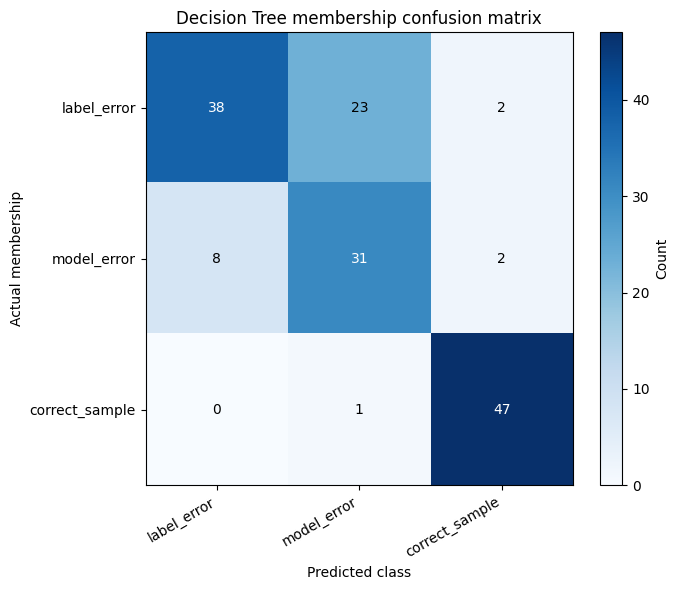

Saved confusion heatmap: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/figures/decision_tree_membership_confusion_matrix.png
Saved per-class metrics: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/validation/decision_tree_per_class_performance_metrics.csv
Saved overall metrics: /content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/validation/decision_tree_overall_performance_metrics.csv


In [30]:
membership_confusion = dt_validation_results[
    "membership_confusion"
].copy()

fig, ax = plt.subplots(figsize=(7, 6))

image = ax.imshow(
    membership_confusion.to_numpy(),
    aspect="auto",
    cmap="Blues",
)

ax.set_xticks(np.arange(len(membership_confusion.columns)))
ax.set_xticklabels(
    membership_confusion.columns,
    rotation=30,
    ha="right",
)

ax.set_yticks(np.arange(len(membership_confusion.index)))
ax.set_yticklabels(membership_confusion.index)

ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual membership")
ax.set_title("Decision Tree membership confusion matrix")

# Choose annotation colour based on cell intensity
threshold = membership_confusion.to_numpy().max() / 2

for row_index in range(membership_confusion.shape[0]):
    for column_index in range(membership_confusion.shape[1]):

        value = int(membership_confusion.iloc[row_index, column_index])

        ax.text(
            column_index,
            row_index,
            value,
            ha="center",
            va="center",
            color="white" if value > threshold else "black",
        )

fig.colorbar(
    image,
    ax=ax,
    label="Count",
)

fig.tight_layout()

fig.savefig(
    DT_MEMBERSHIP_CONFUSION_PNG,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

dt_validation_results["per_class_metrics"].to_csv(
    DT_PERFORMANCE_METRICS_CSV,
    index=False,
)

dt_validation_results["overall_metrics"].to_csv(
    DT_OVERALL_METRICS_CSV,
    index=False,
)

print(f"Saved confusion heatmap: {DT_MEMBERSHIP_CONFUSION_PNG}")
print(f"Saved per-class metrics: {DT_PERFORMANCE_METRICS_CSV}")
print(f"Saved overall metrics: {DT_OVERALL_METRICS_CSV}")

## Cell 18 — Label-error probability threshold precision and recall

In [34]:

check_paths([DT_LABEL_ERROR_PROBABILITY_RASTER])

audited_points["dt_label_error_probability"] = sample_raster_at_points(
    DT_LABEL_ERROR_PROBABILITY_RASTER,
    audited_points,
)

audited_points["dt_label_error_probability"] = pd.to_numeric(
    audited_points["dt_label_error_probability"],
    errors="coerce",
)

# True label error includes actual_class = "1" and "1,2".
audited_points["is_actual_label_error"] = (
    audited_points["actual_class"]
    .astype("string")
    .str.split(",")
    .apply(
        lambda values: (
            "1" in [str(value).strip() for value in values]
            if isinstance(values, list)
            else False
        )
    )
)

# Retrieve the original Decision Tree mask's saved validation metrics.
original_metrics = dt_validation_results["per_class_metrics"]

label_error_class_name = VALIDATION_CLASS_NAMES[1]

original_label_error_metrics = original_metrics.loc[
    original_metrics["class"] == label_error_class_name
]

assert len(original_label_error_metrics) == 1, (
    f"Could not uniquely identify the label-error class: "
    f"{label_error_class_name}"
)

original_precision = float(
    original_label_error_metrics["precision"].iloc[0]
)
original_recall = float(
    original_label_error_metrics["recall"].iloc[0]
)
original_f1 = float(
    original_label_error_metrics["f1"].iloc[0]
)

# Evaluate probability-threshold masks.
threshold_rows = []

valid = (
    audited_points["dt_label_error_probability"].notna()
    & audited_points["actual_class"].notna()
)

actual_positive = (
    audited_points.loc[valid, "is_actual_label_error"]
    .astype(bool)
    .to_numpy()
)

probabilities = (
    audited_points.loc[
        valid, "dt_label_error_probability"
    ]
    .to_numpy(dtype="float64")
)

for threshold in np.arange(0.00, 1.001, 0.05):

    predicted_positive = probabilities >= float(threshold)

    true_positive = int(
        np.sum(predicted_positive & actual_positive)
    )
    false_positive = int(
        np.sum(predicted_positive & ~actual_positive)
    )
    false_negative = int(
        np.sum(~predicted_positive & actual_positive)
    )

    precision = (
        true_positive / (true_positive + false_positive)
        if true_positive + false_positive > 0
        else np.nan
    )

    recall = (
        true_positive / (true_positive + false_negative)
        if true_positive + false_negative > 0
        else np.nan
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if (
            np.isfinite(precision)
            and np.isfinite(recall)
            and precision + recall > 0
        )
        else np.nan
    )

    support_pixels = int(np.sum(predicted_positive))

    threshold_rows.append({
        "probability threshold": f"{int(round(threshold * 100))}%",
        "support pixels": support_pixels,
        "original mask precision": original_precision,
        "original mask recall": original_recall,
        "original mask f1": original_f1,
        "new mask precision": precision,
        "new mask recall": recall,
        "new mask f1": f1,
    })

label_error_threshold_metrics = pd.DataFrame(threshold_rows)

metric_columns = [
    "original mask precision",
    "original mask recall",
    "original mask f1",
    "new mask precision",
    "new mask recall",
    "new mask f1",
]

# Highlight improvements in the new mask only.
highlight_colors = {
    "precision": "#F8B4B4",  # Red
    "recall": "#A7F3D0",     # Green
    "f1": "#BFDBFE",         # Blue
}

def highlight_improvements(row):
    styles = [""] * len(row)

    for metric, color in highlight_colors.items():
        original_col = f"original mask {metric}"
        new_col = f"new mask {metric}"

        original_value = row[original_col]
        new_value = row[new_col]

        if (
            pd.notna(original_value)
            and pd.notna(new_value)
            and new_value > original_value
        ):
            column_index = row.index.get_loc(new_col)

            styles[column_index] = (
                f"background-color: {color}; "
                "color: #111827; "
                "font-weight: bold;"
            )

    return styles

styled_metrics = (
    label_error_threshold_metrics.style
    .format(
        {column: "{:.3f}" for column in metric_columns},
        na_rep="—",
    )
    .apply(highlight_improvements, axis=1)
)

display(styled_metrics)

print(
    "Original mask: Decision Tree class-1 predictions, evaluated "
    "using the saved validation results."
)

print(
    "New mask: audited samples with P(label error) at or above "
    "each probability threshold."
)

print(
    "Support pixels represents the number of audited samples "
    "predicted as label errors at each threshold."
)

print(
    "\nHighlight legend:"
    "\nRed   = New mask precision > original mask precision"
    "\nGreen = New mask recall > original mask recall"
    "\nBlue  = New mask F1 > original mask F1"
    "\nNo highlight = Equal, lower, or undefined metric"
)


,probability threshold,support pixels,original mask precision,original mask recall,original mask f1,new mask precision,new mask recall,new mask f1
0,0%,150,0.826,0.603,0.697,0.420,1.000,0.592
1,5%,109,0.826,0.603,0.697,0.578,1.000,0.733
2,10%,101,0.826,0.603,0.697,0.624,1.000,0.768
3,15%,100,0.826,0.603,0.697,0.630,1.000,0.773
4,20%,94,0.826,0.603,0.697,0.670,1.000,0.803
5,25%,90,0.826,0.603,0.697,0.689,0.984,0.810
6,30%,53,0.826,0.603,0.697,0.811,0.683,0.741
7,35%,53,0.826,0.603,0.697,0.811,0.683,0.741
8,40%,47,0.826,0.603,0.697,0.809,0.603,0.691
9,45%,47,0.826,0.603,0.697,0.809,0.603,0.691


Original mask: Decision Tree class-1 predictions, evaluated using the saved validation results.
New mask: audited samples with P(label error) at or above each probability threshold.
Support pixels represents the number of audited samples predicted as label errors at each threshold.

Highlight legend:
Red   = New mask precision > original mask precision
Green = New mask recall > original mask recall
Blue  = New mask F1 > original mask F1
No highlight = Equal, lower, or undefined metric


## Cell 19 — Export validated points and Decision Tree tables

In [38]:

VALIDATION_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

audited_points_to_save = audited_points.drop(
    columns=["validation_flags_list"],
    errors="ignore",
)

if VALIDATED_POINTS_GPKG.exists():
    VALIDATED_POINTS_GPKG.unlink()

audited_points_to_save.to_file(
    VALIDATED_POINTS_GPKG,
    layer=VALIDATED_POINTS_LAYER,
    driver="GPKG",
)

# Export all saved Decision Tree validation tables.
for table_name, table in dt_validation_results.items():

    if not isinstance(table, pd.DataFrame):
        continue

    output_csv = (
        VALIDATION_TABLE_DIR
        / f"decision_tree_{table_name}.csv"
    )

    table.to_csv(
        output_csv,
        index=True,
    )

    print(output_csv)

# Export original-vs-new mask precision, recall, and F1 table.
label_error_threshold_metrics.to_csv(
    DT_LABEL_ERROR_THRESHOLD_CSV,
    index=False,
)

print(DT_LABEL_ERROR_THRESHOLD_CSV)

# Export the four-mask pixel-removal summary.
LABEL_ERROR_MASK_SUMMARY_CSV = (
    VALIDATION_TABLE_DIR
    / "decision_tree_label_error_mask_summary.csv"
)

label_error_mask_summary.to_csv(
    LABEL_ERROR_MASK_SUMMARY_CSV,
    index=False,
)

print(LABEL_ERROR_MASK_SUMMARY_CSV)

# Experiment metadata.
metadata = {
    "experiment_name": EXPERIMENT_NAME,
    "output_directory": str(OUTPUT_DIR),
    "feature_names": FEATURE_NAMES,
    "class_to_code": CLASS_TO_CODE,

    "decision_tree_max_depth_setting": DECISION_TREE_MAX_DEPTH,
    "decision_tree_actual_depth": int(
        decision_tree.get_depth()
    ),
    "decision_tree_n_leaves": int(
        decision_tree.get_n_leaves()
    ),
    "min_samples_leaf": int(MIN_SAMPLES_LEAF),
    "class_weight": CLASS_WEIGHT,
    "random_seed": int(RANDOM_SEED),
    "balanced_pixels_per_class": int(n_per_class),
    "training_accuracy": float(training_accuracy),

    "random_forest_model": str(RF_MODEL_PATH),
    "random_forest_feature_importance": str(
        RF_FEATURE_IMPORTANCE_CSV
    ),

    "hsic_overall_scores": str(HSIC_OVERALL_CSV),
    "hsic_one_vs_rest_scores": str(HSIC_ONE_VS_REST_CSV),

    "descriptive_statistics": str(DESCRIPTIVE_STATS_CSV),
    "kruskal_wallis_tests": str(KRUSKAL_WALLIS_CSV),
    "pairwise_mann_whitney_tests": str(
        PAIRWISE_MANN_WHITNEY_CSV
    ),

    "label_error_probability_raster": str(
        DT_LABEL_ERROR_PROBABILITY_RASTER
    ),

    "original_label_error_mask_raster": str(
        DT_ORIGINAL_LABEL_ERROR_MASK_RASTER
    ),

    # NEW: 35% probability mask.
    "label_error_35pct_mask_raster": str(
        DT_LABEL_ERROR_35_MASK_RASTER
    ),

    "label_error_55pct_mask_raster": str(
        DT_LABEL_ERROR_55_MASK_RASTER
    ),

    "label_error_85pct_mask_raster": str(
        DT_LABEL_ERROR_85_MASK_RASTER
    ),

    "label_error_mask_summary_csv": str(
        LABEL_ERROR_MASK_SUMMARY_CSV
    ),

    "label_error_threshold_metrics_csv": str(
        DT_LABEL_ERROR_THRESHOLD_CSV
    ),

    "label_error_mask_coding": {
        "0": "retain_for_training",
        "1": "remove_as_suspected_label_error",
        "255": "nodata",
    },

    "selected_label_error_probability_thresholds": {
        "35pct": float(
            LABEL_ERROR_PROBABILITY_THRESHOLD_35
        ),
        "55pct": float(
            LABEL_ERROR_PROBABILITY_THRESHOLD_55
        ),
        "85pct": float(
            LABEL_ERROR_PROBABILITY_THRESHOLD_85
        ),
    },

    "label_error_probability_thresholds": [
        float(value)
        for value in np.arange(0.00, 1.001, 0.05)
    ],

    "n_audited_validation_points": int(
        len(dt_validation_results["evaluated_points"])
    ),
}

DT_METADATA_JSON.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    f"Saved validated points: {VALIDATED_POINTS_GPKG}"
)
print(
    f"Saved metadata: {DT_METADATA_JSON}"
)
print(
    f"Saved mask summary: {LABEL_ERROR_MASK_SUMMARY_CSV}"
)

# Persist all completed outputs to Google Drive.
sync_outputs_to_drive()

/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/validation/decision_tree_one_vs_rest_confusion.csv
/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/validation/decision_tree_membership_confusion.csv
/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/validation/decision_tree_membership_rows.csv
/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/validation/decision_tree_per_class_metrics.csv
/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/validation/decision_tree_overall_metrics.csv
/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/validation/decision_tree_classification_report.csv
/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/validation/decision_tree_evaluated_points.csv
/content/thesis_analysis_outputs/dt_rf500_hsic_rq_analysis_v1/tables/validation/decision_tree_label_error_probability_threshold_metrics.csv
/content/thesis_analysis_outputs/dt_rf500_